# Supplementary Note 1 · The CORDEX2Energy conversion pipeline

How the climate model output becomes the energy quantities the paper analyses: the chains and their
warming-level windows, the bias correction, and each conversion step in turn.

Rendered to the artwork rules of the main figures — **180 mm wide, 5–7 pt DejaVu Sans, PDF + PNG,
no figure titles** — and additionally to Nature's caption rule, which ties the maximum height of a
figure to the length of its legend: at two-column width, **< 50 words → 225 mm, < 150 → 210 mm,
< 300 → 185 mm**, and a caption of 300 words or more is not publishable at any height. Each figure
is preceded by its complete legend, ready to paste into the manuscript.

| | content | figures |
|---|---|---|
| **S1** | the driving GCMs and the warming-level windows | 1 |
| **S2** | European temperature against precipitation and runoff, by season | 1 |
| **S3** | bias-corrected climate variables, annual | 1 |
| **S4** | the same, winter (DJF) | 1 |
| **S5** | the same, spring (MAM) | 1 |
| **S6** | the same, summer (JJA) | 1 |
| **S7** | the same, autumn (SON) | 1 |
| **S8** | total runoff against the channel discharge it is routed into | 1 |
| **S9**–**S10** | the demand model: where its error is, and its fitted cooling-adoption terms | 2 |
| **S11**–**S16** | one figure per conversion step: heating and cooling demand, solar, wind, run-of-river, reservoir inflow | 6 |

Numbering is continuous across the three Supplementary Notes: **Note 1 is S1–S16**.

In [ ]:
%load_ext autoreload
%autoreload 2

In [2]:
import gc
import json
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from cordex2energy.conversion_energy.tyndp import (
    build_c2e_name_to_iso2,
    load_tyndp_country_codes,
)
from cordex2energy_analysis.analysis import compute_sign_agreement, load_warming_level_periods
from cordex2energy_analysis.extremes_analysis import (
    compute_c2e_gwl_field,
    compute_country_gwl_field,
    mask_structural_zeros,
    resolve_gwl_period_definitions,
)
from cordex2energy_analysis.figure_cache import cached, country_monthly, demand_monthly, monthly_totals
from cordex2energy_analysis.plotting_extremes import resolve_model_periods
from cordex2energy_analysis.plotting_paper import (
    MAP_CRS,
    set_map_aspect,
    PaperStyle,
    load_country_geometry,
    plot_country_choropleth,
)
from cordex2energy_analysis.plotting_publication import (
    FS,
    MAP_EXTENT_LAEA,
    _to_laea,
    QUANTITY_CMAP,
    GWL_TITLE,
    season_label,
    _draw_grid,
    DRIVING_GCM_COLORS,
    DRIVING_GCM_ORDER,
    MM, WIDTH,
    MapRow,
    RCM_MARKERS,
    fit_width,
    gwl_handles,
    gwl_maps,
    legend_below,
    model_characterisation_figure,
    panel_gcm_gmst,
    panel_letters,
    publication_rc,
    sign_agreement,
    save,
)


In [3]:
# ── Configuration. The ANALYSIS settings are the paper's, verbatim. ─────────────────────
paths = json.load(open("../paths.json"))
PATH_PROCESSED = Path(paths["path_data_processed"])
PATH_EXTREMES = PATH_PROCESSED / "extremes"
PATH_GWL = PATH_PROCESSED / "energy" / "analysis"
PATH_DEMAND = PATH_PROCESSED / "energy" / "europe" / "demand"
FIGS = Path(paths.get("path_figs", "../figs")) / "si_note1_pipeline"
FIGS.mkdir(parents=True, exist_ok=True)

CLIMATE_SCENARIO = "rcp85"
# The paper's run. The working SI notebook is on DE_2050_LOW_2050_... which is a DIFFERENT
# simulation (no c2edem demand model, no freecool cooling treatment); both exist on disk, so the
# mismatch is silent. Asserted below against the main-figures notebook.
RUN_TAG = "DE_2050_c2edem_LOW_2050_freecool_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600"
WARMING_LEVELS = [1.5, 2.0, 3.0]
ROBUSTNESS_FRACTION = 2 / 3
SEASON_ORDER = ["DJF", "MAM", "JJA", "SON"]
SEASON_MONTHS = {"DJF": [12, 1, 2], "MAM": [3, 4, 5], "JJA": [6, 7, 8], "SON": [9, 10, 11]}

ZONE_ORDER = ["Iberian_Peninsula", "South_East", "Central_Western",
              "Central_Eastern", "Nordic", "British_Isles"]
ZONE_LABELS = {"Iberian_Peninsula": "Iberia", "South_East": "South-East",
               "Central_Western": "Central-West", "Central_Eastern": "Central-East",
               "Nordic": "Nordic", "British_Isles": "British Isles"}
GWL_COLORS = ["#4A90E2", "#F5A623", "#D0021B"]

_main = json.load(open("paper_figures_publication.ipynb"))
_tags = {line.split('"')[1] for cell in _main["cells"] if cell["cell_type"] == "code"
         for line in cell["source"] if line.startswith("RUN_TAG =")}
assert _tags == {RUN_TAG}, f"run tag drifted from the main figures: {_tags} vs {RUN_TAG}"
print("run tag matches paper_figures_publication.ipynb")
print("figures ->", FIGS)

run tag matches paper_figures_publication.ipynb
figures -> /home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/figs/si_note1_pipeline


In [4]:
# ── The chains, their GWL windows, and the PaperStyle every figure is drawn with ────────
models = sorted("_".join(p.name.split("_")[:-1])
                for p in (PATH_EXTREMES / "residual_load").glob(f"*_{CLIMATE_SCENARIO}")
                if (p / RUN_TAG).exists())

period_defs, _, _ = resolve_gwl_period_definitions(
    warming_levels=WARMING_LEVELS, models=models, chain_meta_path="../models.json",
    gwl_yaml_path=PATH_PROCESSED / "cmip5_warming_levels_all_ens_1861_1900.yml",
    climate_scenario=CLIMATE_SCENARIO)
period_names = list(period_defs.keys())
REFERENCE, WARMEST = period_names[0], period_names[-1]
ROBUSTNESS_THRESHOLD = int(np.ceil(len(models) * ROBUSTNESS_FRACTION))

STYLE = PaperStyle(
    zones=ZONE_ORDER, zone_labels=ZONE_LABELS, period_names=period_names,
    gwl_colors=dict(zip(period_names, GWL_COLORS)), driver_palette={}, duration_palette={},
    season_order=SEASON_ORDER, n_models=len(models),
    robustness_threshold=ROBUSTNESS_THRESHOLD, spread="iqr")

# ETRS89-LAEA (EPSG:3035), the EU's equal-area projection: drawn areas are true areas. The earlier
# lon/lat maps were stretched to their panel box and inflated the north.
countries = load_country_geometry(
    PATH_PROCESSED / "maps" / "natural_earth" / "ne_50m_admin_0_countries.geojson", crs=MAP_CRS)
# Simplified geometry for the choropleth figures, as in Figures 2 and 3: at ~55 mm per map a 0.02 deg
# displacement is ~0.02 mm, an order of magnitude below print resolution, and it halves the vector
# file. The gridded figures draw only country BOUNDARIES, so they use it too.
countries_print = countries.copy()
countries_print["geometry"] = countries.geometry.simplify(2000.0)   # metres, ~0.02 deg
assert set(countries_print["ISO2"]) == set(countries["ISO2"]), "simplification dropped a country"

# The hatching uses the vectorised sign agreement: analysis.compute_sign_agreement goes through
# apply_ufunc(vectorize=True), i.e. a Python loop over every grid cell, which costs 7 s per 426x510
# field and 84 s per six-row figure. Assert the two agree exactly rather than trusting the swap.
_probe = xr.DataArray(np.random.RandomState(0).randn(len(models), 40, 50),
                      dims=("model", "lat", "lon")).where(
                          np.random.RandomState(1).rand(len(models), 40, 50) > 0.15)
assert (compute_sign_agreement(_probe, model_dim="model").values
        == sign_agreement(_probe).values).all(), "the fast sign agreement is not the reference one"

print(f"{len(models)} chains | robustness {ROBUSTNESS_THRESHOLD}/{len(models)} "
      f"| periods {period_names}")

9 chains | robustness 6/9 | periods ['+1.5°C', '+2.0°C', '+3.0°C']


In [5]:
# ── The gridded GWL means (batch job: scripts/compute_climate_means_gwl.py) ─────────────
GRID_SEASON_RENAME = {"Winter": "DJF", "Spring": "MAM", "Summer": "JJA", "Fall": "SON"}
# Qrouted is NOT here: it is the routed counterpart of mrro rather than another climate field,
# and it has its own figure (S8), which is where the comparison belongs. Listing it as a sixth
# variable put the same quantity twice in one figure at two stages of processing.
CLIMATE_VARIABLES = ["tas", "rsds", "sfcWind", "pr", "mrro"]
ROUTING_VARIABLES = ["mrro", "Qrouted"]      # S8: what the river routing does to the runoff
CLIMATE_CMAPS = {"tas": "inferno", "rsds": "plasma", "sfcWind": "GnBu", "pr": "YlGnBu",
                 "mrro": "PuBu", "Qrouted": "GnBu",
                 "pv": "plasma", "wind": "Greens"}
CLIMATE_UNITS = {"tas": "K", "rsds": "W m$^{-2}$", "sfcWind": "m s$^{-1}$", "pr": "mm d$^{-1}$",
                 "mrro": "kg m$^{-2}$", "Qrouted": "m$^3$ s$^{-1}$",
                 "pv": "capacity factor", "wind": "capacity factor"}
ROBUST_ABS_VMAX = {"Qrouted"}      # channel-concentrated: a plain max saturates the scale


def load_gwl_grids(kind: str, seasonal: bool = False) -> dict:
    folder = PATH_GWL / ("seasonal" if seasonal else "annual") / "gwl"
    suffix = {("climate", False): "_climate", ("climate", True): "_climate_meteorological",
              ("", False): "", ("", True): "_meteorological"}[(kind, seasonal)]
    grids = {}
    for level, period in zip(WARMING_LEVELS, period_names):
        ds = xr.open_dataset(folder / f"mean_gwl_{int(round(level * 10))}{suffix}.nc")
        if seasonal:
            ds = ds.assign_coords(
                season=[GRID_SEASON_RENAME[str(s)] for s in ds["season"].values]
            ).sel(season=SEASON_ORDER)
        grids[period] = ds
    shapes = {p: (ds.sizes.get("model"), ds.sizes["lat"], ds.sizes["lon"])
              for p, ds in grids.items()}
    if len(set(shapes.values())) > 1:
        raise RuntimeError(f"GWL {kind or 'energy'} files disagree on shape: {shapes}")
    return grids


climate_annual = load_gwl_grids("climate")
climate_seasonal = load_gwl_grids("climate", seasonal=True)

# All six variables must be present in both products at all three levels; assert rather than
# filter, so a genuinely missing variable is a failure and not a silently shorter figure.
for name, grids in (("annual", climate_annual), ("seasonal", climate_seasonal)):
    for variable in CLIMATE_VARIABLES + ["Qrouted"]:
        missing = [p for p in period_names if variable not in grids[p].data_vars]
        assert not missing, f"{variable} missing from the {name} files at {missing}"
        change_type = grids[period_names[0]][variable].attrs.get("change_type")
        assert change_type in ("absolute", "percent"), f"{variable}: change_type={change_type!r}"
assert climate_annual[REFERENCE]["tas"].attrs["change_type"] == "absolute", \
    "a percentage change in kelvin is meaningless"
print(f"climate grids: {CLIMATE_VARIABLES} (+ Qrouted, drawn in S8)")


def climate_rows(grids, season=None, variables=None):
    """One MapRow per climate variable. Gridded rows keep a continuous ramp: bin edges on a smooth
    field would invent boundaries that are not in the data.

    ``variables`` defaults to CLIMATE_VARIABLES; S8 passes ROUTING_VARIABLES to draw mrro against
    the discharge it is routed into.
    """
    rows = []
    for variable in variables or CLIMATE_VARIABLES:
        attrs = grids[period_names[0]][variable].attrs

        def field(period, variable=variable):
            da = grids[period][variable]
            return da.sel(season=season) if season is not None and "season" in da.dims else da

        rows.append(MapRow(
            label=variable, field=field, cmap=CLIMATE_CMAPS[variable], kind="grid",
            unit=CLIMATE_UNITS[variable],
            change="absolute" if attrs["change_type"] == "absolute" else "percent",
            # Both ramps named EXPLICITLY, not inherited. The builder's default changed to
            # RdBu_r (red = increase) so that Figures 2 and 3 share one rule; these maps must
            # NOT follow it, because "blue is wetter" is a standing hydrological convention for
            # pr / mrro / Qrouted and flipping it would make more rainfall read as red. tas keeps
            # red = warming, which is the same convention pointing the other way. Leaving either
            # to the default would have repainted this figure the moment that default moved.
            change_cmap="RdBu_r" if attrs["change_type"] == "absolute" else "RdBu",
            clabel=(f"\u0394 {CLIMATE_UNITS[variable]}"
                    if attrs["change_type"] == "absolute" else "% change"),
            robust_abs_vmax=variable in ROBUST_ABS_VMAX))
    return rows

# The ENERGY grids, loaded through the same function so the conversion figures and the climate
# figures they derive from describe one product.
energy_annual = load_gwl_grids("")
energy_seasonal = load_gwl_grids("", seasonal=True)
print(f"energy grids: {sorted(energy_annual[REFERENCE].data_vars)}")


climate grids: ['tas', 'rsds', 'sfcWind', 'pr', 'mrro'] (+ Qrouted, drawn in S8)
energy grids: ['pv', 'wind']


## 1 · Inset panels for main Figure 1, the conversion pipeline

The schematic is assembled outside these notebooks. What this section renders are the three panels
that sit beside its demand stage, showing what the chain actually emits at that point: a per-chain
time series, one panel per warming level, on a shared vertical scale so the level shift is the
visible difference.

They are deliberately not analysis figures. Spanish cooling demand is the illustration because it is
the demand term that grows fastest under warming, and because the ensemble spread on it is wide
enough to make the point that the pipeline emits nine chains, not one number.

Written to a `pipeline/` subdirectory rather than beside the numbered figures: they are ingredients
of main Figure 1, not supplementary figures in their own right, and the artwork checker walks only the top
level.

The pipeline schematic itself is main-text **Figure 1**; its legend lives in `paper_figures_publication.ipynb`.


In [7]:
# ── The pipeline illustration panels ────────────────────────────────────────────────────
# Spain by NAME: the demand product indexes countries by name, not ISO2.
COUNTRY, COUNTRY_LABEL, WINDOW_YEARS = "Spain", "Spain", 20
PIPELINE_FIGS = FIGS / "pipeline"
PIPELINE_FIGS.mkdir(parents=True, exist_ok=True)

# ── Annual cooling demand for one country, per chain, per warming level ─────────────────
# The stored product is HOURLY power in GW, so a year's sum is already GW-hours and /1000 gives
# TWh. (An earlier version multiplied by 24 on the assumption of daily means and put Spain at
# 337 TWh/yr of cooling, an order of magnitude above its entire residential electricity demand.)
# A TOTAL rather than a mean is the point: longer, hotter summers add cooling hours as well as
# degrees, and a mean over the year would divide that back out.
started = pd.Timestamp.now()
rows = []
for model in models:
    with xr.open_dataset(PATH_DEMAND / f"{model}_{CLIMATE_SCENARIO}.nc") as dataset:
        series = dataset["cooling_demand"].sel(country=COUNTRY)
        annual = series.resample(time="1YE").sum().load() / 1e3            # GW-hours -> TWh
    windows = resolve_model_periods(period_defs, model)
    for period in period_names:
        window = windows.get(period)
        if window is None:
            continue
        block = annual.sel(time=slice(str(window[0]), str(window[1])))
        for index, value in enumerate(block.values, start=1):
            rows.append(dict(model=model, period=period, year_in_window=index,
                             twh=float(value)))
cooling = pd.DataFrame(rows)
print(f"{len(cooling):,} rows in {(pd.Timestamp.now() - started).seconds}s")

# Nine chains and twenty years in every level, or the three figures are not comparable.
for _period in period_names:
    _block = cooling[cooling.period == _period]
    _counts = _block.groupby("model")["year_in_window"].count()
    assert len(_counts) == len(models), f"{_period}: {len(_counts)} chains, expected {len(models)}"
    assert set(_counts) == {WINDOW_YEARS}, \
        f"{_period}: window lengths {sorted(set(_counts))}, expected {WINDOW_YEARS}"
print(f"every level carries {len(models)} chains x {WINDOW_YEARS} years")

# A sanity bound on the unit arithmetic, not on the physics: Spanish cooling electricity is of
# order 10 TWh/yr today, so anything outside 1-100 means the GW-to-TWh conversion is wrong again.
_span = cooling["twh"]
assert 1.0 < _span.median() < 100.0, \
    f"annual cooling of {_span.median():.1f} TWh/yr is not a plausible unit for {COUNTRY_LABEL}"

print(f"\nAnnual cooling demand, {COUNTRY_LABEL} (TWh/yr), across chains and years:")
for _period in period_names:
    _v = cooling[cooling.period == _period]["twh"]
    print(f"  {_period}  median {_v.median():5.1f}   chain spread of the 20-year mean "
          f"{cooling[cooling.period == _period].groupby('model')['twh'].mean().min():5.1f} - "
          f"{cooling[cooling.period == _period].groupby('model')['twh'].mean().max():5.1f}")


540 rows in 6s
every level carries 9 chains x 20 years

Annual cooling demand, Spain (TWh/yr), across chains and years:
  +1.5°C  median  12.1   chain spread of the 20-year mean  10.5 -  13.9
  +2.0°C  median  13.9   chain spread of the 20-year mean  12.7 -  16.0
  +3.0°C  median  18.9   chain spread of the 20-year mean  17.5 -  23.1


  pipeline_cooling_spain_1p5    58.4 x  41.2 mm   panel 28.5 mm   pdf 33 kB  png 113 kB
  pipeline_cooling_spain_2p0    58.4 x  41.2 mm   panel 28.5 mm   pdf 33 kB  png 109 kB
  pipeline_cooling_spain_3p0    58.4 x  41.2 mm   panel 28.5 mm   pdf 33 kB  png 136 kB
all three share y = (np.float64(7.473258), np.float64(31.636164))
each figure draws 9 chains + median, 20 points each

Ensemble-median annual cooling demand (TWh/yr): +1.5°C 12.0  +2.0°C 13.8  +3.0°C 19.1


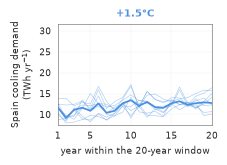

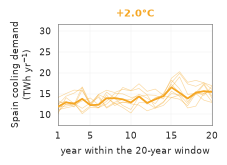

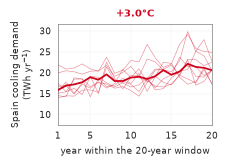

In [8]:
# ── One figure per warming level, sharing a single y limit ──────────────────────────────
# The limit is computed across ALL levels first. Drawn per figure it would autoscale to each
# level's own range, and three panels that each fill their axes would show no warming signal at
# all — which is the one thing the set is for.
Y_TOP = cooling["twh"].max() * 1.06
# NOT anchored at zero. The values run 10-30 TWh/yr, so a zero baseline left the bottom third of
# every panel empty and squeezed the chain bundle — the spread these figures exist to show — into
# what was left. Truncating is safe here in a way it would not be on bars: the three panels share
# this one limit, so the level shift between warming levels is still read off the same ruler.
Y_BOTTOM = cooling["twh"].min() * 0.94
# Derived from the warming levels rather than written out against the period names: those names
# are formatted by resolve_gwl_period_definitions, and a hardcoded key would KeyError silently
# somewhere else in the notebook if that formatting ever changed.
SLUG = {name: f"{level:.1f}".replace(".", "p")
        for name, level in zip(period_names, WARMING_LEVELS)}


def pipeline_panel(period, color):
    """Nine chains thin, the ensemble median bold, in this level's colour."""
    fig, ax = plt.subplots(figsize=(WIDTH * 0.32, 38 * MM))
    block = cooling[cooling.period == period]
    for model, chain in block.groupby("model"):
        chain = chain.sort_values("year_in_window")
        ax.plot(chain["year_in_window"], chain["twh"], lw=0.5, color=color, alpha=0.45, zorder=2)
    median = block.groupby("year_in_window")["twh"].median()
    ax.plot(median.index, median.values, lw=1.4, color=color, zorder=3)

    ax.set_ylim(Y_BOTTOM, Y_TOP)
    ax.set_xlim(1, WINDOW_YEARS)
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.set_xlabel("year within the 20-year window", fontsize=FS["label"])
    ax.set_ylabel(f"{COUNTRY_LABEL} cooling demand\n(TWh yr$^{{-1}}$)", fontsize=FS["label"])
    ax.set_title(period, fontsize=FS["title"], fontweight="bold", color=color)
    ax.tick_params(labelsize=FS["tick"])
    ax.grid(True, color="0.93", lw=0.3)
    ax.set_axisbelow(True)
    return fig


_limits, _lines = set(), {}
with publication_rc():
    for _period, _color in zip(period_names, GWL_COLORS):
        _fig = pipeline_panel(_period, _color)
        # A third of the page each, so the three sit in a flowchart row without rescaling.
        fit_width(_fig, target_mm=58)
        save(_fig, f"pipeline_cooling_{COUNTRY.lower()}_{SLUG[_period]}", PIPELINE_FIGS,
             max_width_mm=60)
        # Measured off the figures that were actually WRITTEN, not off a second set drawn to be
        # measured: those would share a limit by construction and the assertion would prove nothing.
        _limits.add(tuple(round(v, 6) for v in _fig.axes[0].get_ylim()))
        _lines[_period] = [line.get_xydata() for line in _fig.axes[0].lines]
plt.show()

assert len(_limits) == 1, f"the three pipeline figures do not share a y limit: {_limits}"
print(f"all three share y = {sorted(_limits)[0]}")

# Nine chains and a median, each of twenty points, in every figure.
for _period, _drawn in _lines.items():
    assert len(_drawn) == len(models) + 1, \
        f"{_period}: {len(_drawn)} lines drawn, expected {len(models)} chains plus the median"
    _lengths = {len(d) for d in _drawn}
    assert _lengths == {WINDOW_YEARS}, f"{_period}: line lengths {sorted(_lengths)}"
print(f"each figure draws {len(models)} chains + median, {WINDOW_YEARS} points each")

_medians = {p: float(cooling[cooling.period == p].groupby("year_in_window")["twh"].median().mean())
            for p in period_names}
print("\nEnsemble-median annual cooling demand (TWh/yr): "
      + "  ".join(f"{p} {v:.1f}" for p, v in _medians.items()))
assert _medians[period_names[-1]] > _medians[period_names[0]], \
    "cooling demand no longer rises with warming; the three-figure set has nothing to show"


## 2 · S1: the driving GCMs and the warming-level windows

The nine chains are not nine independent samples: large-scale circulation comes from the driving
GCM, so the two chains sharing a driver inherit its response. Panel **a** places those five drivers
in the CMIP5 ensemble they are drawn from; panel **b** turns the same warming levels into the dates
each chain is actually evaluated over.

This merges what were two separate figures. The crossing-year strip that used to accompany **a** is
dropped: it answered "when does each CMIP5 run cross" for the whole ensemble, which **b** already
answers for the nine chains that matter here.

> **Supplementary Figure 1 | The driving GCMs and the warming-level windows they define.**
> **a**, Global-mean surface air temperature (GSAT, area-weighted near-surface `tas`) anomaly against 1861–1900 for every CMIP5 model with an
> RCP8.5 run, annual means. Grey lines are the ensemble; coloured lines are the five GCMs that drive
> the nine EURO-CORDEX chains. Dashed rules mark the three warming levels the paper is stated at.
> **b**, The 20-year window each chain is evaluated over at each level, with its years printed
> beside it. A window opens when its driving GCM's smoothed global warming first reaches the level,
> so chains sharing a driver share a window and the windows fall in different decades for
> different chains — which is why every result is a mean over a chain's own window rather than over
> a fixed period.

In [10]:
# ── The chain table: which GCM drives which RCM, and when each reaches every level ──────
# The nine chains are listed in full here; the figure below draws the five distinct timings.
RCM_DISPLAY = {"CNRM-ALADIN63": "ALADIN63", "MOHC-HadREM3-GA7-05": "HadREM3-GA7-05"}
GCM_DISPLAY = {"CNRM-CERFACS-CNRM-CM5_r1i1p1": "CNRM-CM5",
               "ICHEC-EC-EARTH_r12i1p1": "EC-EARTH",
               "MOHC-HadGEM2-ES_r1i1p1": "HadGEM2-ES",
               "MPI-M-MPI-ESM-LR_r1i1p1": "MPI-ESM-LR",
               "NCC-NorESM1-M_r1i1p1": "NorESM1-M"}


def split_chain(model):
    """(RCM, driving GCM) of a chain name: the leading token, then everything after it."""
    return model.split("_")[0], "_".join(model.split("_")[1:])


_seen = {gcm for _, gcm in map(split_chain, models)}
assert _seen <= set(GCM_DISPLAY), f"unlabelled driving GCM(s): {sorted(_seen - set(GCM_DISPLAY))}"
assert {rcm for rcm, _ in map(split_chain, models)} <= set(RCM_DISPLAY), "unlabelled RCM"

rows = []
for model in models:
    rcm, gcm = split_chain(model)
    row = {"RCM": RCM_DISPLAY[rcm], "driving GCM": GCM_DISPLAY[gcm]}
    for period in period_names:
        window = period_defs[period].get(model)
        row[period] = f"{int(window[0])}-{int(window[1])}" if window else "n/a"
    rows.append(row)
chain_table = pd.DataFrame(rows).sort_values(["driving GCM", "RCM"]).reset_index(drop=True)
print(f"The {len(chain_table)} chains and their warming-level windows:\n")
print(chain_table.to_string(index=False))

# One representative chain per driving GCM. The windows are a property of the GCM, so the two RCMs
# sharing one give identical bars; assert that rather than assume it, because a silent difference
# would mean the figure is showing one RCM's timing and claiming it is the GCM's.
gcm_rows = []
for model in models:
    _, gcm = split_chain(model)
    if gcm not in [g for g, _ in gcm_rows]:
        gcm_rows.append((gcm, model))
# Alphabetical by display name, so the figure's rows are in the table's order. Chain-discovery
# order would put EC-EARTH last for no reason a reader can see (it has only one RCM, so it sorts
# late by full chain name).
gcm_rows.sort(key=lambda pair: GCM_DISPLAY[pair[0]])
for gcm, representative in gcm_rows:
    for model in models:
        if split_chain(model)[1] != gcm:
            continue
        for period in period_names:
            assert period_defs[period].get(model) == period_defs[period].get(representative), \
                f"{model} and {representative} share a GCM but not the {period} window"
print(f"\n{len(gcm_rows)} distinct driving GCMs across {len(models)} chains")

The 9 chains and their warming-level windows:

           RCM driving GCM    +1.5°C    +2.0°C    +3.0°C
      ALADIN63    CNRM-CM5 2022-2041 2036-2055 2059-2078
HadREM3-GA7-05    CNRM-CM5 2022-2041 2036-2055 2059-2078
HadREM3-GA7-05    EC-EARTH 2009-2028 2026-2045 2052-2071
      ALADIN63  HadGEM2-ES 2015-2034 2027-2046 2046-2065
HadREM3-GA7-05  HadGEM2-ES 2015-2034 2027-2046 2046-2065
      ALADIN63  MPI-ESM-LR 2007-2026 2026-2045 2051-2070
HadREM3-GA7-05  MPI-ESM-LR 2007-2026 2026-2045 2051-2070
      ALADIN63   NorESM1-M 2024-2043 2040-2059 2064-2083
HadREM3-GA7-05   NorESM1-M 2024-2043 2040-2059 2064-2083

5 distinct driving GCMs across 9 chains


In [11]:
# ── S3: the CMIP5 ensemble behind the five driving GCMs ─────────────────────────────────
# Two cached products, both on the paper's own 1861-1900 baseline. The GMST table is written by
# scripts/compute_cmip5_gmst.py (a ~29 GB read of the raw CMIP5 archive, reduced to ~90 kB); the
# crossing years come from the same warming-level YAML that defines every GWL window in the paper.
gmst = xr.open_dataset(PATH_PROCESSED / f"cmip5_gmst_annual_{CLIMATE_SCENARIO}.nc")["gmst_anomaly"]

_all_windows = load_warming_level_periods(
    PATH_PROCESSED / "cmip5_warming_levels_all_ens_1861_1900.yml", WARMING_LEVELS, None)
crossing = pd.DataFrame(
    [dict(model=model, ensemble=ensemble, warming_level=level, start_year=window["start_year"])
     for (model, ensemble), scenarios in _all_windows.items()
     for level, window in scenarios.get(CLIMATE_SCENARIO, {}).items()])

# The member each chain actually used. EC-EARTH is r12i1p1; taking r1i1p1 would put a different
# realisation on the figure under the paper's label.
DRIVING_MEMBERS = {"CNRM-CM5": "r1i1p1", "EC-EARTH": "r12i1p1", "HadGEM2-ES": "r1i1p1",
                   "MPI-ESM-LR": "r1i1p1", "NorESM1-M": "r1i1p1"}
DRIVING_KEYS = {gcm: f"{gcm}_{member}" for gcm, member in DRIVING_MEMBERS.items()}

print(f"GMST table: {gmst.sizes['model']} models x {gmst.sizes['year']} years, "
      f"{int(gmst.year.min())}-{int(gmst.year.max())}")
print(f"crossing years: {len(crossing)} runs over {crossing.model.nunique()} models")

# 1. The background ensemble has to be an ensemble, and it has to contain the five.
assert gmst.sizes["model"] >= 35, f"only {gmst.sizes['model']} CMIP5 models in the GMST table"
_absent = [k for k in DRIVING_KEYS.values() if k not in set(gmst.model.values)]
assert not _absent, f"driving GCM(s) missing from the GMST table: {_absent}"

# 2. An anomaly is zero over its own baseline. A non-zero value would mean the baseline slice
#    missed the data — a calendar or units fault — not that the model is warm.
_base = gmst.sel(year=slice(1861, 1900)).mean("year")
assert np.allclose(_base.values, 0.0, atol=1e-9), \
    f"GMST baseline is not zero: max |mean| = {np.abs(_base.values).max():.3g} K"

# 3. THE check that matters: panel b's crossing years must be the very windows the rest of the
#    paper is computed over. Two readings of one YAML that disagree would mean this figure
#    describes an ensemble the results did not come from.
for _gcm, _member in DRIVING_MEMBERS.items():
    _cordex = next(c for c in models if GCM_DISPLAY[split_chain(c)[1]] == _gcm)
    for _level, _period in zip(WARMING_LEVELS, period_names):
        _here = crossing[(crossing.model == _gcm) & (crossing.ensemble == _member)
                         & (crossing.warming_level == _level)]["start_year"].iloc[0]
        _there = int(period_defs[_period][_cordex][0])
        assert int(_here) == _there, \
            f"{_gcm} +{_level}: S3b says {int(_here)}, the paper's windows say {_there}"
print(f"crossing years agree with period_defs for all {len(DRIVING_MEMBERS)} driving GCMs")

print(f"\nFirst year of the {CLIMATE_SCENARIO} window, driving GCMs against the ensemble:")
for _level in WARMING_LEVELS:
    _block = crossing[crossing.warming_level == _level]
    _five = {g: int(_block[(_block.model == g) & (_block.ensemble == m)]["start_year"].iloc[0])
             for g, m in DRIVING_MEMBERS.items()}
    print(f"  +{_level}°C  ensemble median {int(_block.start_year.median())}  "
          f"(n={len(_block)})   " + "  ".join(f"{g} {y}" for g, y in sorted(_five.items())))

print(f"\n2081-2100 mean anomaly (K), driving GCMs against the ensemble:")
_end = gmst.sel(year=slice(2081, 2100)).mean("year")
_ens = _end.to_series().sort_values()
for _gcm, _key in sorted(DRIVING_KEYS.items()):
    _rank = int((_ens < float(_end.sel(model=_key))).sum()) + 1
    print(f"  {_gcm:<12}{float(_end.sel(model=_key)):+5.2f}   rank {_rank}/{len(_ens)}")
print(f"  {'ensemble':<12}{float(_ens.median()):+5.2f}   median")

GMST table: 42 models x 240 years, 1861-2100
crossing years: 270 runs over 39 models
crossing years agree with period_defs for all 5 driving GCMs

First year of the rcp85 window, driving GCMs against the ensemble:
  +1.5°C  ensemble median 2016  (n=90)   CNRM-CM5 2022  EC-EARTH 2009  HadGEM2-ES 2015  MPI-ESM-LR 2007  NorESM1-M 2024
  +2.0°C  ensemble median 2030  (n=90)   CNRM-CM5 2036  EC-EARTH 2026  HadGEM2-ES 2027  MPI-ESM-LR 2026  NorESM1-M 2040
  +3.0°C  ensemble median 2052  (n=90)   CNRM-CM5 2059  EC-EARTH 2052  HadGEM2-ES 2046  MPI-ESM-LR 2051  NorESM1-M 2064

2081-2100 mean anomaly (K), driving GCMs against the ensemble:
  CNRM-CM5    +4.13   rank 14/42
  EC-EARTH    +4.45   rank 22/42
  HadGEM2-ES  +5.09   rank 34/42
  MPI-ESM-LR  +4.52   rank 24/42
  NorESM1-M   +3.75   rank 8/42
  ensemble    +4.44   median


  S1_driving_gcms_and_windows  166.5 x  75.0 mm   panel 54.4 mm   pdf 108 kB  png 435 kB


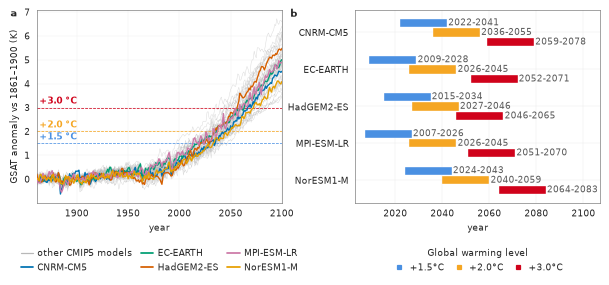

In [12]:
def _fit_window_labels(ax, starts, ends, *, fig):
    """Widen the x axis so the rightmost window label ends inside it.

    SOLVED, not measured-then-added. The previous version measured the label in data units and
    added it to the limit -- but setting the limit changes the very transform the measurement came
    from, so the axis grew and the label needed more room than it had just been given, and
    "2064-2083" ended 0.7 pt from the page edge. In PIXELS the relation is fixed: a label of L
    pixels inside an axis of W pixels leaves D = S(1 - L/W) for the data, so the span that fits both
    is D / (1 - L/W). One draw, one solve, no iteration.
    """
    fig.canvas.draw()
    probe = ax.text(0, 0, "8888-8888", fontsize=FS["tick"])
    label_px = probe.get_window_extent(fig.canvas.get_renderer()).width
    probe.remove()
    axis_px = ax.get_window_extent().width
    data_span = (max(ends) + 1.5) - (min(starts) - 4)
    # 1.14, not 1.0: the label starts 1.5 years past the bar end, and a factor that only just fits
    # left the glyph 2 px from the spine, which reads as touching it. The margin is cheap -- it
    # costs a few years of empty axis on the right, where there are no bars anyway.
    span = data_span / max(1.0 - 1.14 * label_px / axis_px, 0.35)
    ax.set_xlim(min(starts) - 4, min(starts) - 4 + span)


def figure_s1():
    """a, the drivers inside CMIP5; b, the windows those drivers define for the nine chains.

    One figure because the panels are two halves of one statement: a level is a temperature in a,
    and the same level is a set of dates in b. They were separate figures while the ensemble strip
    sat between them; without it they are adjacent.
    """
    fig, axes = plt.subplots(1, 2, figsize=(WIDTH, 62 * MM),
                             gridspec_kw={"wspace": 0.30, "width_ratios": (1.0, 1.0)})
    ax_a, ax_b = axes
    panel_gcm_gmst(ax_a, gmst, driving=DRIVING_KEYS, warming_levels=WARMING_LEVELS,
                   level_colors=dict(zip(WARMING_LEVELS, GWL_COLORS)))

    # b -- one row per driving GCM, three bars each, the window printed beside every bar.
    height = 0.26
    starts, ends = [], []
    for y, (gcm, model) in enumerate(gcm_rows):
        for k, period in enumerate(period_names):
            window = period_defs[period].get(model)
            if window is None:
                continue
            start, end = int(window[0]), int(window[1])
            starts.append(start)
            ends.append(end)
            ax_b.barh(y + (k - 1) * height, end - start + 1, left=start, height=height * 0.86,
                      color=STYLE.gwl_colors[period], edgecolor="white", linewidth=0.3, zorder=3)
            ax_b.text(end + 1.5, y + (k - 1) * height, f"{start}-{end}", va="center", ha="left",
                      fontsize=FS["tick"], color="0.35")
    ax_b.set_yticks(range(len(gcm_rows)))
    ax_b.set_yticklabels([GCM_DISPLAY[gcm] for gcm, _ in gcm_rows], fontsize=FS["label"])
    ax_b.invert_yaxis()
    ax_b.set_xlabel("year", fontsize=FS["label"])
    ax_b.set_xlim(min(starts) - 4, max(ends) + 1.5)
    ax_b.tick_params(labelsize=FS["tick"])
    ax_b.grid(True, axis="x", color="0.90", lw=0.3)
    ax_b.set_axisbelow(True)

    fit_width(fig)
    _fit_window_labels(ax_b, starts, ends, fig=fig)

    # A legend PER PANEL, not one shared row. The two keys mean different things -- a line colour in
    # a is a model, a bar colour in b is a warming level -- and pooling them put "+1.5 °C" beside
    # "NorESM1-M" as though they were the same kind of entry.
    gcm_handles = [plt.Line2D([], [], color="0.72", lw=1.0)]
    gcm_labels = ["other CMIP5 models"]
    for gcm in DRIVING_GCM_ORDER:
        if gcm in DRIVING_KEYS:
            gcm_handles.append(plt.Line2D([], [], color=DRIVING_GCM_COLORS[gcm], lw=1.4))
            gcm_labels.append(gcm)
    legend_below(fig, [ax_a], gcm_handles, gcm_labels, ncol=3)
    level_handles, level_labels = gwl_handles(STYLE)
    legend_below(fig, [ax_b], level_handles, list(level_labels), ncol=3, title=GWL_TITLE)
    panel_letters(fig, [("a", ax_a), ("b", ax_b)])
    return fig


with publication_rc():
    fig = figure_s1()
    save(fig, "S1_driving_gcms_and_windows", FIGS)
plt.show()

## 3 · S2: European temperature against precipitation and runoff, by season

How far apart the chains' European responses are, in the two hydrological variables the conversion
depends on. Runoff matters here because it is what the hydropower conversion consumes; precipitation
is one step removed from the energy system.

**Why this figure is seasonal.** An annual version says something the seasons contradict: annually,
seven of the nine chains dry in precipitation while seven of the nine gain runoff. That inversion is
an averaging artefact — precipitation's annual mean follows its largest signal, summer drying, and
runoff's follows its largest, the winter gain. Within a season the two never disagree. Spring is the
diagnostic case: precipitation falls in seven of nine chains while runoff rises in eight of nine,
which is the snowmelt signature — warming shifts winter precipitation from snow to rain and releases
the pack earlier, so more water runs off where less falls. Shown annually the figure would state the
opposite of what happens in every individual season, so the annual version is not shown.

**How the means are taken.** Each point is one chain's change between its own +1.5 °C and +3.0 °C
windows, area-averaged over the analysis domain (30–72.6 °N, 12 °W–39 °E) with cos-latitude
weighting. Temperature and precipitation are averaged over the whole domain; **runoff over land
only**, because the bias-corrected product stores zero over the sea and including it would dilute
every value by the land fraction, a factor of about 1.6 here.

The CMIP5 ensemble cannot be shown: HadGEM2-ES and EC-EARTH archive no runoff anywhere in the
CMIP5 tree, and they drive three of the nine chains.

> **Supplementary Figure 2 | Change in European precipitation and runoff against warming, by
> season.** Each marker is one EURO-CORDEX chain's change between its own +1.5 °C and +3.0 °C
> windows, coloured by driving GCM and shaped by regional model, so chains sharing a driver share a
> colour. **Top row**, precipitation; **bottom row**, runoff; columns are the meteorological
> seasons. Area means over the analysis domain with cos-latitude weighting — runoff over land only,
> since the product stores zero over sea. Horizontal rules are zero change. Precipitation and runoff
> move together within every season: both rise in winter, both fall in summer. Spring is the
> exception that shows the mechanism, precipitation falling while runoff rises as earlier snowmelt
> releases the pack.

In [14]:
# ── S2: the seasonal change in European temperature, precipitation and runoff ───────────
# Read from the SEASONAL gridded GWL means, the same product S3–S7 are drawn from, so this
# figure and those describe one dataset. Two masks, deliberately different: the CERRA footprint for
# temperature and precipitation, land only for runoff -- see the note above.
GRID_SEASONS = {"Winter": "DJF", "Spring": "MAM", "Summer": "JJA", "Fall": "SON"}
EXTENT = {"lat": slice(30, 72.6), "lon": slice(-12, 39)}
cerra_mask = xr.open_dataarray(PATH_PROCESSED / "cerra_valid_mask.nc")
land_mask = xr.open_dataarray(PATH_PROCESSED / "european_land_mask.nc")
print(f"masks: CERRA {100 * float(cerra_mask.mean()):.1f}% of the box, "
      f"land {100 * float(land_mask.mean()):.1f}%")


def area_mean(field, mask):
    """cos-latitude weighted spatial mean over a mask, as in scripts/compute_european_t_p.py."""
    weights = np.cos(np.deg2rad(field["lat"]))
    field = field.where(mask)
    return float(field.weighted(weights.broadcast_like(field).where(mask).fillna(0.0))
                 .mean(dim=["lat", "lon"]))


_seasonal = {level: xr.open_dataset(
    PATH_GWL / "seasonal" / "gwl" / f"mean_gwl_{int(round(level * 10))}_climate_meteorological.nc"
).sel(**EXTENT) for level in (min(WARMING_LEVELS), max(WARMING_LEVELS))}
_low, _high = min(WARMING_LEVELS), max(WARMING_LEVELS)
_chains = [str(m) for m in _seasonal[_low]["model"].values]

seasonal_change = pd.DataFrame([
    dict(model=chain.replace(f"_{CLIMATE_SCENARIO}", ""), season=GRID_SEASONS[grid_season],
         dT=area_mean(_seasonal[_high]["tas"].sel(model=chain, season=grid_season), cerra_mask)
            - area_mean(_seasonal[_low]["tas"].sel(model=chain, season=grid_season), cerra_mask),
         dP=area_mean(_seasonal[_high]["pr"].sel(model=chain, season=grid_season), cerra_mask)
            - area_mean(_seasonal[_low]["pr"].sel(model=chain, season=grid_season), cerra_mask),
         dR=area_mean(_seasonal[_high]["mrro"].sel(model=chain, season=grid_season), land_mask)
            - area_mean(_seasonal[_low]["mrro"].sel(model=chain, season=grid_season), land_mask))
    for chain in _chains for grid_season in GRID_SEASONS])

print(f"\n  {'season':<7}{'dT (K)':>9}{'dP (mm/d)':>22}{'d runoff (mm/d)':>26}")
for _season in SEASON_ORDER:
    _b = seasonal_change[seasonal_change.season == _season]
    print(f"  {_season:<7}{_b.dT.median():>+8.2f} "
          f"{_b.dP.median():>+10.3f} ({int((_b.dP < 0).sum())}/{len(_b)} drier)"
          f"{_b.dR.median():>+13.3f} ({int((_b.dR < 0).sum())}/{len(_b)} less)")

# The claim the caption makes, and the reason the figure is seasonal rather than annual: within a
# season the two variables agree in direction, and spring is the case where they part company.
for _season in ("DJF", "JJA"):
    _b = seasonal_change[seasonal_change.season == _season]
    assert np.sign(_b.dP.median()) == np.sign(_b.dR.median()), (
        f"{_season}: precipitation and runoff no longer move together "
        f"({_b.dP.median():+.3f} vs {_b.dR.median():+.3f})")
_spring = seasonal_change[seasonal_change.season == "MAM"]
assert (_spring.dP < 0).sum() > len(_spring) / 2 and (_spring.dR > 0).sum() > len(_spring) / 2, (
    "spring no longer shows the snowmelt signature (precipitation down, runoff up), which is the "
    "mechanism this figure exists to make visible")
print("\nwithin-season agreement holds in DJF and JJA; spring keeps the snowmelt signature")

masks: CERRA 99.9% of the box, land 53.9%

  season    dT (K)             dP (mm/d)           d runoff (mm/d)
  DJF       +1.62     +0.036 (2/9 drier)       +0.085 (2/9 less)
  MAM       +1.59     -0.015 (7/9 drier)       +0.045 (1/9 less)
  JJA       +1.78     -0.098 (8/9 drier)       -0.048 (8/9 less)
  SON       +1.61     +0.001 (4/9 drier)       +0.004 (4/9 less)

within-season agreement holds in DJF and JJA; spring keeps the snowmelt signature


  S2_european_t_p_runoff_seasonal 179.7 x 103.4 mm   panel 32.6 mm   pdf 70 kB  png 181 kB


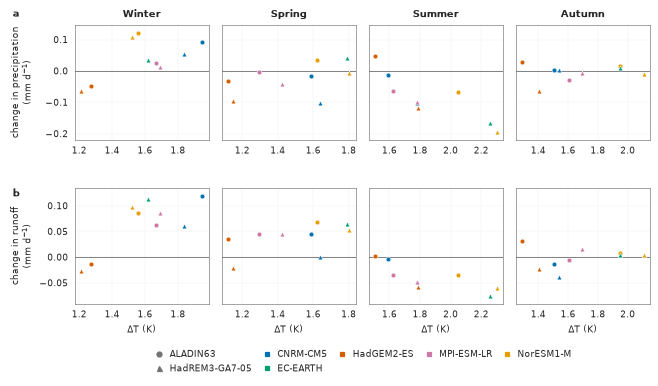

In [15]:
def figure_s2():
    """Two rows, four seasons. One row per hydrological variable, sharing the warming axis.

    Each row shares a y scale across the seasons: drawn per panel, summer's large drying and
    autumn's near-zero would fill their axes identically and the figure would say the seasons are
    alike, which is the opposite of its point.
    """
    fig, axes = plt.subplots(2, len(SEASON_ORDER), figsize=(WIDTH, 88 * MM),
                             gridspec_kw={"hspace": 0.42, "wspace": 0.10})
    meta = {m["id"]: m for m in json.load(open("../models.json"))["model_chains"]}
    CORDEX_TO_CMIP5 = {"CNRM-CERFACS-CNRM-CM5": "CNRM-CM5", "MOHC-HadGEM2-ES": "HadGEM2-ES",
                       "NCC-NorESM1-M": "NorESM1-M", "MPI-M-MPI-ESM-LR": "MPI-ESM-LR",
                       "ICHEC-EC-EARTH": "EC-EARTH"}
    for row, (column, label) in enumerate((("dP", "change in precipitation\n(mm d$^{-1}$)"),
                                           ("dR", "change in runoff\n(mm d$^{-1}$)"))):
        span = seasonal_change[column]
        pad = 0.08 * (span.max() - span.min())
        for col, season in enumerate(SEASON_ORDER):
            ax = axes[row, col]
            block = seasonal_change[seasonal_change.season == season]
            ax.axhline(0.0, color="0.45", lw=0.7, zorder=1)
            for _, point in block.iterrows():
                info = meta.get(point["model"], {})
                gcm = CORDEX_TO_CMIP5.get(info.get("gcm"), info.get("gcm"))
                ax.plot(point["dT"], point[column],
                        RCM_MARKERS.get(info.get("rcm"), "o"), ms=3.8,
                        color=DRIVING_GCM_COLORS.get(gcm, "0.5"), mec="white", mew=0.4, zorder=3)
            ax.set_ylim(span.min() - pad, span.max() + pad)
            ax.tick_params(labelsize=FS["tick"])
            ax.grid(color="0.93", lw=0.3)
            ax.set_axisbelow(True)
            if row == 0:
                ax.set_title(season_label(season), fontsize=FS["title"], fontweight="bold")
            if col:
                ax.set_yticklabels([])
            else:
                ax.set_ylabel(label, fontsize=FS["label"])
            if row == 1:
                ax.set_xlabel("ΔT (K)", fontsize=FS["label"])
    fit_width(fig)
    # One x for both row labels: the rows' tick labels differ in width ("-0.05" vs "0.1").
    fig.align_ylabels(axes[:, 0])
    handles = [plt.Line2D([], [], color="0.45", marker=marker, ls="none", ms=4)
               for marker in RCM_MARKERS.values()]
    labels = [RCM_LABELS.get(name, name) for name in RCM_MARKERS]
    handles += [plt.Line2D([], [], color=DRIVING_GCM_COLORS[g], marker="s", ls="none", ms=3.4)
                for g in DRIVING_GCM_ORDER]
    labels += list(DRIVING_GCM_ORDER)
    legend_below(fig, list(axes.ravel()), handles, labels, ncol=5)
    panel_letters(fig, list(zip("ab", [axes[0, 0], axes[1, 0]])))
    return fig


RCM_LABELS = {"CNRM-ALADIN63": "ALADIN63", "MOHC-HadREM3-GA7-05": "HadREM3-GA7-05"}
with publication_rc():
    fig = figure_s2()
    save(fig, "S2_european_t_p_runoff_seasonal", FIGS)
plt.show()

## 4 · S3–S7: the bias-corrected climate variables

The five variables every conversion downstream reads, after bias correction. Runoff appears here as
`mrro`, the water each grid cell sheds; what the river routing then does with it is Supplementary
Fig. S8, since that is a processing step rather than another climate field.

> **Supplementary Figure 3 | The bias-corrected EURO-CORDEX climate variables, annual mean.**
> Rows are, from top: **tas**, near-surface air temperature; **rsds**, surface downwelling shortwave
> radiation; **sfcWind**, near-surface wind speed; **pr**, precipitation; and **mrro**, total
> runoff. All are empirical-quantile-mapping
> bias-corrected against CERRA (91-day window, 99 quantiles, trained 1991–2020). Column 1 is the
> absolute field at +1.5 °C; the rest give the change from it as the median across nine chains, in
> kelvin for **tas** and as a percentage for everything else. Hatching marks cells where fewer than
> six of nine chains agree on the sign.

> **Supplementary Figure 4 | The bias-corrected climate variables in winter (December–February,
> DJF).** The five variables of Supplementary Fig. S3 for the winter season, the contiguous
> December-to-February triplet; rows, columns, scales and hatching as in Supplementary Fig. S3.

> **Supplementary Figure 5 | The bias-corrected climate variables in spring (March–May, MAM).** As
> Supplementary Fig. S4, for spring.

> **Supplementary Figure 6 | The bias-corrected climate variables in summer (June–August, JJA).** As
> Supplementary Fig. S4, for summer.

> **Supplementary Figure 7 | The bias-corrected climate variables in autumn (September–November,
> SON).** As Supplementary Fig. S4, for autumn.

  [ticks] wanted 4 inside [63.3284, 249.518] but the closest round set has 3: [np.float64(80.0), np.float64(160.0), np.float64(240.0)]
  S3_climate_annual            131.2 x 171.6 mm   panel 30.5 mm   pdf 4809 kB  png 4582 kB


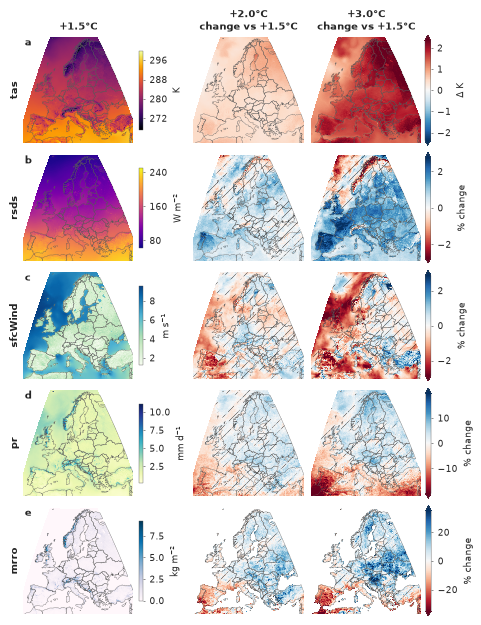

In [17]:
with publication_rc():
    fig, row_axes = gwl_maps(climate_rows(climate_annual), countries_print, STYLE,
                             sign_agreement, height_mm=174)
    panel_letters(fig, list(zip("abcde", row_axes)), inside=True)
    save(fig, "S3_climate_annual", FIGS)
plt.show()

  S4_climate_DJF               140.9 x 183.9 mm   panel 33.5 mm   pdf 5315 kB  png 5228 kB
  S5_climate_MAM               140.2 x 183.9 mm   panel 33.5 mm   pdf 5689 kB  png 5318 kB
  S6_climate_JJA               140.9 x 183.9 mm   panel 33.5 mm   pdf 5762 kB  png 5305 kB
  S7_climate_SON               140.9 x 183.9 mm   panel 33.5 mm   pdf 5315 kB  png 5354 kB


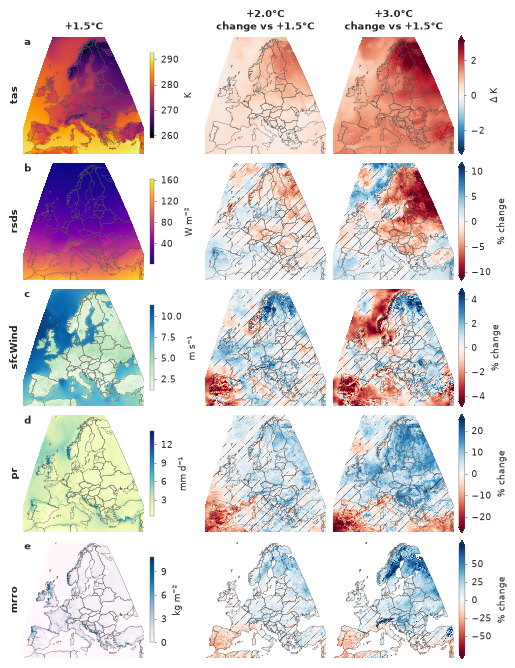

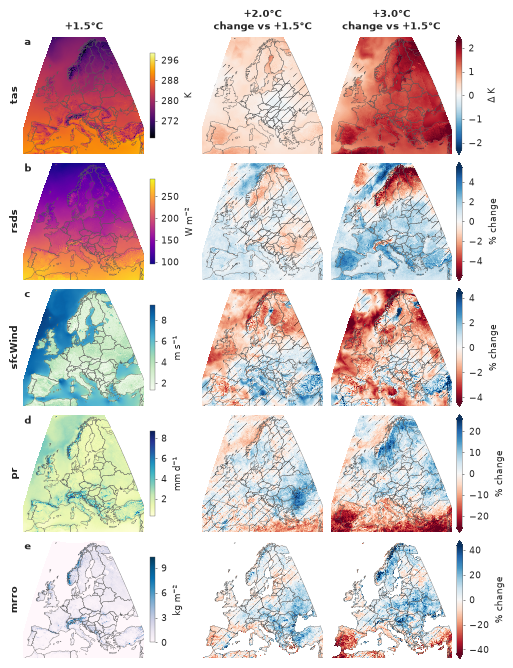

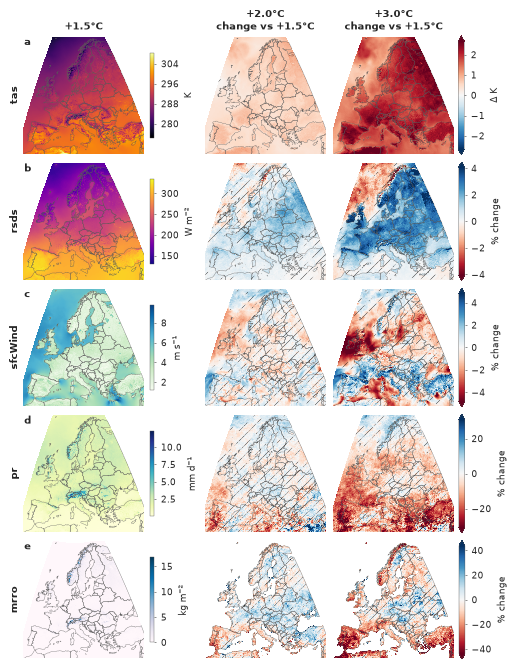

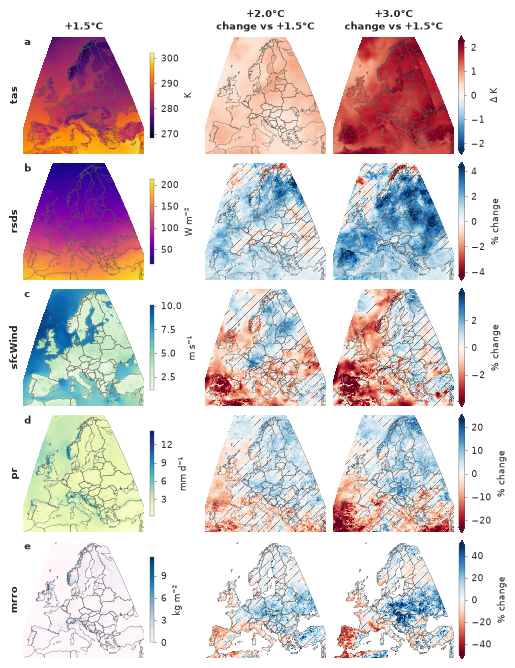

In [18]:
# One numbered figure per season (S4-S7), so each can be cited on its own.
CLIMATE_SEASON_STEMS = {"DJF": "S4_climate_DJF", "MAM": "S5_climate_MAM", "JJA": "S6_climate_JJA",
                        "SON": "S7_climate_SON"}
with publication_rc():
    for season in SEASON_ORDER:
        fig, row_axes = gwl_maps(climate_rows(climate_seasonal, season=season), countries_print,
                                 STYLE, sign_agreement, height_mm=186)
        panel_letters(fig, list(zip("abcde", row_axes)), inside=True)
        save(fig, CLIMATE_SEASON_STEMS[season], FIGS)
        plt.show()

## 5 · S8: what the river routing does to the runoff

The paper carries runoff twice, and the two are not interchangeable. **mrro** is the water each grid
cell sheds — diffuse, spread over the whole land surface. **Qrouted** is that water after the mRM
river model has moved it downhill through the channel network, which is what actually arrives at a
turbine. The hydropower conversion reads the routed field, so the step between these two panels is
one the rest of the note depends on.

This is a single climate, not a change: the figure is about what routing *does*, and the warming
response of both fields is already in Supplementary Figs. S3–S7. Showing them side by side at one
level puts the whole comparison in one glance.

**Why the two panels use different colour scales.** Routing turns a smooth field into an extremely
skewed one. Across the domain `Qrouted` runs from 1 m³ s⁻¹ at the median wet cell to 6838 at the
Danube mouth — nearly four orders of magnitude, against a factor of twenty for `mrro`. On a linear
scale only the largest half-dozen rivers are visible at all and everything else is blank, which
makes the panel look like an error rather than a river network. A **logarithmic** scale shows the
network as it is: main stems dark, tributaries pale, the drainage hierarchy legible.

> **Supplementary Figure 8 | Total runoff and the channel discharge it is routed into, at
> +1.5 °C.** **a**, **mrro**, runoff generated per grid cell, ensemble median, on a linear scale
> clipped at its 99th percentile. **b**, **Qrouted**, the same water after the mRM river model
> routes it downhill through the channel network — the quantity the hydropower conversion reads —
> on a **logarithmic** scale, without which only the largest rivers are distinguishable from zero.
> Cells below the colour range are left blank. Routing conserves the water and redistributes it:
> counting cells that carry more than 1 % of their field's maximum, the diffuse field in **a**
> covers 49 % of the domain and the network in **b** 3 %. Almost every land cell drains somewhere,
> so this is a statement about where the water is, not about where it is non-zero.

  S8_runoff_routing            179.9 x  74.1 mm   panel 69.2 mm   pdf 539 kB  png 1277 kB
  cells above 1% of the field maximum:  mrro 49%   Qrouted 3%
  Qrouted spans 2.33e-07 to 6838 m3 s-1, median of positive cells 1.08


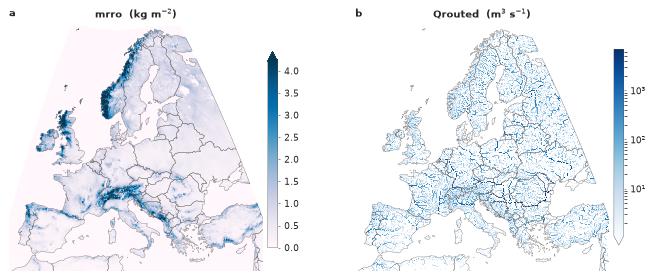

In [20]:
def figure_s8():
    """mrro beside Qrouted at one warming level: what the routing model does, spatially.

    A bespoke 1x2 rather than `gwl_maps`, which is built around a reference column plus change
    columns. There is no change here, and the two panels deliberately do NOT share a scale: they
    are different quantities in different units (kg m-2 against m3 s-1) and the whole point is that
    one is diffuse and the other concentrated.
    """
    fig, axes = plt.subplots(1, 2, figsize=(WIDTH, 66 * MM), gridspec_kw={"wspace": 0.06})
    level = period_names[0]
    fields = climate_annual[level]

    for ax, (variable, cmap) in zip(axes, (("mrro", "PuBu"), ("Qrouted", "Blues"))):
        field = fields[variable].median("model")
        finite = field.values[np.isfinite(field.values)]
        positive = finite[finite > 0]
        if variable == "Qrouted":
            # Log, and the reason is in the data: the positive cells span 1.08 m3 s-1 at the median
            # to 6838 at the Danube mouth. Linear, the 99th percentile is 490, so 99 % of the
            # network renders as the bottom 7 % of the ramp -- one white sheet with six blue
            # threads. vmin at the positive median starts the ramp where the channels start.
            floor = max(float(np.percentile(positive, 50)), 1e-3)
            norm = mcolors.LogNorm(vmin=floor, vmax=float(np.nanmax(finite)))
            # Masked BELOW THE FLOOR, not merely at zero. Routing leaves a trace almost everywhere
            # -- the field runs down to 2e-7 m3 s-1 and is positive on 53 % of the grid -- so
            # masking only exact zeros painted every hillside the palest blue and the channels had
            # to compete with it. Below the floor there is no channel worth drawing.
            field = field.where(field >= floor)
            extend = "min"
        else:
            norm = mcolors.Normalize(vmin=0.0, vmax=float(np.percentile(positive, 99)))
            extend = "max"

        colormap = plt.get_cmap(cmap).copy()
        colormap.set_bad("white")
        mesh = _draw_grid(ax, field, crs=countries_print.crs, cmap=colormap, norm=norm)
        _, _, footprint = _to_laea(field, countries_print.crs)
        countries_print.clip(footprint).boundary.plot(ax=ax, color="0.35", linewidth=0.25)
        ax.set_xlim(*MAP_EXTENT_LAEA[:2])
        ax.set_ylim(*MAP_EXTENT_LAEA[2:])
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        ax.set_aspect("equal")                     # equal-area projection: keep true shapes
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_title(f"{variable}  ({CLIMATE_UNITS[variable]})", fontsize=FS["title"], fontweight="bold")

        bar = fig.colorbar(mesh, ax=ax, fraction=0.030, pad=0.015, extend=extend)
        bar.ax.tick_params(labelsize=FS["tick"])
        bar.outline.set_linewidth(0.3)

    fit_width(fig)
    panel_letters(fig, list(zip("ab", list(axes))))
    return fig


with publication_rc():
    fig = figure_s8()
    save(fig, "S8_runoff_routing", FIGS)
plt.show()

# The concentration claim, measured. NOT as "cells above zero": almost every land cell drains
# somewhere, so `Qrouted > 0` is true on 53 % of the grid and says nothing -- it was the wrong test
# and it would have let the caption's numbers drift unchecked. Concentration is about where the
# water IS, so the threshold is a fixed fraction of each field's own maximum.
_mrro = climate_annual[period_names[0]]["mrro"].median("model")
_qrouted = climate_annual[period_names[0]]["Qrouted"].median("model")
SIGNIFICANT = 0.01          # of the field maximum
_share = {name: float((field > SIGNIFICANT * float(field.max())).mean())
          for name, field in (("mrro", _mrro), ("Qrouted", _qrouted))}
_positive = _qrouted.where(_qrouted > 0)
print(f"  cells above {SIGNIFICANT:.0%} of the field maximum:  "
      f"mrro {100 * _share['mrro']:.0f}%   Qrouted {100 * _share['Qrouted']:.0f}%")
print(f"  Qrouted spans {float(_positive.min()):.2e} to {float(_qrouted.max()):.0f} m3 s-1, "
      f"median of positive cells {float(_positive.median()):.2f}")
assert _share["Qrouted"] < 0.2 * _share["mrro"], (
    "Qrouted is no longer concentrated relative to mrro "
    f"({100 * _share['Qrouted']:.0f}% against {100 * _share['mrro']:.0f}%); the figure's whole "
    "claim is that routing gathers a diffuse field into a sparse one")

## 6 · How the demand model performs, and what its cooling terms are

The heating and cooling series the conversion figures show come from a degree-day model whose
coefficients are fitted to **JRC-IDEES** national energy statistics on **CERRA** degree days. This
section characterises those coefficients before they are applied.

**What can and cannot be claimed.** There is no independent measurement to validate against:
JRC-IDEES is the calibration target, and is itself a statistical construct — energy balances
disaggregated to end uses — rather than a measurement of space heating. TYNDP is a scenario, not an
observation, and it disagrees with JRC by roughly a factor of two on cooling. What follows is
therefore **agreement with the calibration target, and the identifiability of the fitted
parameters**. It is not external validation, and none is available.

**Heating** is a single linear coefficient, `P_heat_elec = electrified_share x P_heat_thermal`, with
no intercept, no saturation and no level anchor. Evaluated as applied, `P.HDD` reproduces observed
national annual heating energy with a median NRMSE of **7.9 %** (range 3.5-43 %), landing within
±10 % of observed in **75 % of 583 country-years**. The mean level agrees to 0.1 % in the median,
but that is by construction rather than evidence: the through-origin slope is calibrated to
reproduce it. What is *not* calibrated is which years are cold, and that is where the error sits.
Splitting the mean squared error into its three exact parts puts a median **90 %** of it in the
correlation term — the model carries the right level and very nearly the right amount of
year-to-year movement, but places that movement in the wrong years, at a median interannual
correlation of 0.55.

The other half of the coefficient deserves as much attention as the fit does. `electrified_share`
converts the all-carrier slope into the electric part the power system sees; it spans **53x** across
countries (Romania 0.014 to Malta 0.768, median 0.116) and is frozen at a **single JRC year** —
2023 for most countries, 2015 for the UK on the fallback edition. No future electrification of heat
is carried by the demand model itself; that enters later, through the TYNDP target.

**Cooling** is fitted per sector in per-capita space, pooled across countries with a shared
curvature and intensity and a per-country baseload — the space-for-time assumption, that warm
countries today stand in for cool countries' future. Pooling is what makes the curvature
identifiable at all, since within any one country the degree days barely moved over 2000-2020.

| | heating | cooling |
|---|---|---|
| fit to the calibration target | NRMSE median **7.9 %** (3.5-43 %), 75 % of country-years within ±10 % | NRMSE median **23.8 %** (2.0-77.5 %) |
| where that error sits, bias / variance / correlation | 0 / 10 / **90 %** | **42** / 34 / 24 % |
| country held out (gap-fill rule) | Σ\|error\| 685 of 3327 TWh/yr (**21 %**) | Σ\|error\| 19.6 of 39.9 TWh/yr (**49 %**) |
| level anchor | none | median 1.12, IQR 1.03-1.28, range 0.32-1.44 |


### S9: demand model performance

> **Supplementary Figure 9 | Where the demand model's error is, and whether it is in the right
> years.** **a**, **b**, Normalised root-mean-square error of modelled annual national energy
> against JRC-IDEES, per country, over 2000-2020. **c**, **d**, The year-to-year correlation
> between the two. Each scale is classed and shared between the fuels; dark is worse in the upper
> row and better in the lower one. The two greys are different statements: hatched mid grey are the nine
> countries the study models that JRC-IDEES does not cover, so they are gap-filled and have nothing
> to be evaluated against — Albania, Bosnia and Herzegovina, Kosovo, Montenegro, North Macedonia,
> Norway, Serbia, Switzerland, Ukraine — and light grey is outside the study's country set. Malta
> and Luxembourg are drawn as circles, being too small to fill at this size.
> Levels agree by calibration (median modelled/observed 0.999 heating, 1.145 cooling after its
> anchor), so the error is almost all in the year-to-year variation. Split into the three standard
> terms of the mean squared error — squared bias, variance (σ_m − σ_o)², and lack of correlation
> 2σ_mσ_o(1 − r), the last two resolving the bias-variance split's variance — the median heating
> error is 0 % bias, 10 % variance and **90 % lack of correlation**: the model carries the right
> level and nearly the right interannual amplitude, but in the wrong years (median r = 0.55).
> Cooling divides 42 / 34 / 24 % and is larger (median NRMSE 23.8 % against 7.9 %), yet its
> correlation is highest exactly where cooling is large (Italy and France 0.90, Greece 0.86) and
> negative where it is negligible (Sweden, the United Kingdom).


### S10: the fitted cooling adoption terms

> **Supplementary Figure 10 | The fitted air-conditioning adoption share, and how sharply its
> curvature is determined.** **a**, The saturating adoption share at the fitted curvatures for the
> residential and service sectors, against the published Heat Roadmap Europe values (dashed). Ticks
> mark each country's mean annual CDD over 2000-2020, the fit window. The service curve saturates
> inside the observed range while the residential one does not, so residential adoption still grows
> roughly linearly across the whole projected range. **b**, Every candidate the selection rule
> considered: each country subset crossed with either a separate weather-insensitive baseload per
> country or one shared by all. The bar is the set of curvatures fitting within 1 % of that
> candidate's own best residual sum of squares — **how sharply the data pin the curvature**, not a
> spread between countries. Curvature governs extrapolation, since the adoption share is evaluated
> far outside the observed range under warming, so a candidate that fits well but leaves the
> curvature undetermined is of no use: R² ≥ 0.85 admits a candidate and the **narrowest bar** then
> wins. Selecting on R² instead would take a residential curvature 13 times smaller. The chosen
> specification differs between sectors, which is the rule working rather than an inconsistency —
> per-country baselines absorb the between-country contrast that identifies the curvature for
> residential, whereas for service a single shared baseline fits so poorly it determines nothing.

In [24]:
# ── S9-S10: how the demand model performs, and what its cooling adoption terms are ───────
# Everything reuses the DERIVATION module (`demand_coefficients`); nothing refits the production
# coefficients. The point is to characterise them, not to reproduce them.
from cordex2energy.conversion_energy import demand_coefficients as dc

DEMAND_INPUTS = PATH_PROCESSED / "energy" / "inputs"
COOL_SECTORS = {"res": "cool_res_gwh", "srv": "cool_srv_gwh"}
SECTOR_LABEL = {"res": "residential", "srv": "service"}
BASELOAD_LABEL = {"FE": "per-country baseload", "noFE": "shared baseload"}

demand_coefs = pd.read_csv(DEMAND_INPUTS / "demand_coefficients.csv", index_col=0)
THETA = {s: float(demand_coefs[f"theta_cool_{s}"].dropna().iloc[0]) for s in COOL_SECTORS}


def _annual_dd(name):
    """National annual degree days from the cached CERRA aggregation, built by the same
    `dc.national_annual_degree_days` the coefficient derivation uses."""
    frame = pd.read_csv(DEMAND_INPUTS / f"{name}_eurostat_cerra_allcountries.csv", index_col=0)
    frame.index = frame.index.astype(str).str.slice(0, 4).astype(int)
    return frame.astype(float)


hdd_annual, cdd_annual = _annual_dd("hdd"), _annual_dd("cdd")
jrc = {}
for _name in demand_coefs.index:
    _series = dc.load_jrc_fec_series(DEMAND_INPUTS / "JRC_2023", _name, "2023")
    if _series is None:
        _series = dc.load_jrc_fec_series(DEMAND_INPUTS / "JRC_2015", _name, "2015")
    if _series is not None:
        jrc[_name] = _series
# 2015 for cooling (mid fit window, the anchor basis) and 2020 for heating, matching the two
# gap-fills in the derivation: `derive_cooling_coefficients` takes 2015, `fill_missing_coefficients`
# defaults to 2020. The hold-out panels below must use the same years as the rule they test.
POP_COOL = dc.world_bank_population(DEMAND_INPUTS / "World_bank_population.csv", "2015")
POP_HEAT = dc.world_bank_population(DEMAND_INPUTS / "World_bank_population.csv", "2020")
COOL_YEARS = [y for y in dc.COOL_FIT_YEARS if y in cdd_annual.index]
FITTED = sorted(c for c in jrc if c in cdd_annual.columns and c in POP_COOL.index)
POP_M = {c: float(POP_COOL[c]) / 1e6 for c in FITTED}
print(f"JRC countries with degree days and population: {len(FITTED)}")

# ── Heating and cooling, as applied, per country ────────────────────────────────────────
# Evaluated directly on the forms the pipeline runs: through-origin `P*HDD` for heating and the
# sector-split saturating model with its level anchor for cooling. An earlier version scored a
# DETRENDED heating model, which is a model nobody runs.
#
# The heating LEVEL is calibrated, so modelled and observed country means agree to a few per cent by
# construction -- which is why S9 maps the ERROR and the CORRELATION rather than the level: a
# scatter of modelled against observed was a diagonal line restating its own calibration.
def _spread_row(name, observed, modelled):
    """Level, spread, and the standard three-term split of the mean squared error.

        MSE = (mean_m - mean_o)^2 + (sd_m - sd_o)^2 + 2 sd_m sd_o (1 - r)
              squared bias         variance          lack of correlation

    The names are the usual ones for this decomposition (Kobayashi & Salam 2000). The coarse
    bias-variance split is the same identity read one level up -- MSE = bias^2 + Var(m - o), the
    second and third terms being that variance separated into a difference of standard deviations
    and a lack of correlation.

    The third term is the one a comparison of level and spread cannot see: a model can carry the
    right mean and the right amount of year-to-year movement and still place that movement in the
    wrong years. For heating it is ~90 % of the error.
    """
    sd_o, sd_m = observed.std(), modelled.std()
    r = float(np.corrcoef(observed, modelled)[0, 1])
    mse = float(np.mean((modelled - observed) ** 2))
    bias2 = float((modelled.mean() - observed.mean()) ** 2)
    variance = float((sd_m - sd_o) ** 2)
    lack_of_corr = float(2 * sd_m * sd_o * (1 - r))
    return dict(country=name,
                observed=observed.mean(), modelled=modelled.mean(),
                obs_lo=np.percentile(observed, 10), obs_hi=np.percentile(observed, 90),
                mod_lo=np.percentile(modelled, 10), mod_hi=np.percentile(modelled, 90),
                nrmse_pct=100 * np.sqrt(mse) / observed.mean(),
                bias_pct=100 * (modelled.mean() - observed.mean()) / observed.mean(),
                r=r, mse=mse,
                bias_share=bias2 / mse, var_share=variance / mse,
                corr_share=lack_of_corr / mse,
                n=int(observed.size))


_rows, _pooled = [], []
for _name, _series in jrc.items():
    if _name not in hdd_annual.columns or _name not in demand_coefs.index:
        continue
    _idx = hdd_annual.index.intersection(_series.index)
    _x = hdd_annual.loc[_idx, _name].to_numpy(float)
    _y = _series.loc[_idx, "heat_thermal_gwh"].to_numpy(float)
    _ok = np.isfinite(_x) & np.isfinite(_y) & (_x > 0) & (_y > 0)
    _x, _y = _x[_ok], _y[_ok]
    if _x.size < 8:
        continue
    _model = float(demand_coefs.loc[_name, "P_heat_thermal"]) * 24.0 * _x
    _rows.append(_spread_row(_name, _y / 1e3, _model / 1e3))
    _pooled.append(_model / _y)
heating_perf = pd.DataFrame(_rows).set_index("country").sort_values("observed", ascending=False)
# Every country-year rather than every country: the section prose quotes this one, and it is the
# statement a reader of the model wants -- how far off a single national year can be.
heat_ratio = np.concatenate(_pooled)

_smoothed_cdd = cdd_annual.rolling(5, min_periods=1).mean()
_rows = []
for _name in demand_coefs.index:
    if _name not in jrc or _name not in cdd_annual.columns:
        continue
    _ratio = float(demand_coefs.loc[_name, "corrective_ratio_cool"])
    if not np.isfinite(_ratio):
        continue
    _obs = sum(jrc[_name][v].reindex(COOL_YEARS) for v in COOL_SECTORS.values()) / 1e3
    _model = 0.0
    for _sector in COOL_SECTORS:
        _th = float(demand_coefs.loc[_name, f"theta_cool_{_sector}"])
        _B = float(demand_coefs.loc[_name, f"B_cool_{_sector}"])
        _P = float(demand_coefs.loc[_name, f"P_cool_{_sector}"])
        _share = 1.0 - np.exp(-_th * _smoothed_cdd.loc[COOL_YEARS, _name])
        # B is a power [GW] -> x8760 h; P is [GW per degC.day] on ANNUAL degree days -> x24 h.
        _model = _model + (_B * 8760 + _P * (cdd_annual.loc[COOL_YEARS, _name] * _share) * 24) / 1e3
    _model = _model * _ratio
    _ok = np.isfinite(_obs) & np.isfinite(_model) & (_obs > 0)
    if _ok.sum() < 8:
        continue
    _rows.append(_spread_row(_name, _obs[_ok].to_numpy(float), _model[_ok].to_numpy(float)))
cooling_perf = pd.DataFrame(_rows).set_index("country").sort_values("observed", ascending=False)

# ── The two map fields, keyed the way the choropleth helper expects ─────────────────────
# `plot_country_choropleth` is keyed by the ISO2 code the energy data uses, while the demand
# coefficients are keyed by full country name. `dc._ISO_TO_NAME` is the derivation's OWN table, so
# inverting it cannot drift from the coefficients the maps describe. Two coding quirks: JRC writes
# Greece "EL" where Natural Earth has "GR", and `load_country_geometry` already maps Natural
# Earth's "GB" to the "UK" the c2e data uses.
# NOT `build_c2e_name_to_iso2` (which cell 34 uses for the demand product): that inverts the TYNDP
# workbook, which is both an Excel read this cell has no other need for and the wrong authority --
# these values describe the JRC fit, so the JRC table is what they must be keyed by.
JRC_NAME_TO_ISO2 = {name: ("GR" if iso == "EL" else iso) for iso, name in dc._ISO_TO_NAME.items()}

# The nine countries the study models but JRC-IDEES does not cover. They get their OWN fill rather
# than being left to the choropleth's grey, because that grey also covers Morocco, Turkey and
# Russia -- everything outside the study's country set -- and "not in the study" and "in the study
# but with no data to evaluate against" are different statements that must not share a colour.
NO_JRC_ISO2 = {"Albania": "AL", "Bosnia and Herzegovina": "BA", "Kosovo": "XK",
               "Montenegro": "ME", "North Macedonia": "MK", "Norway": "NO",
               "Serbia": "RS", "Switzerland": "CH", "Ukraine": "UA"}

nrmse_iso2 = {"heating": heating_perf.nrmse_pct.rename(index=JRC_NAME_TO_ISO2),
              "cooling": cooling_perf.nrmse_pct.rename(index=JRC_NAME_TO_ISO2)}
corr_iso2 = {"heating": heating_perf.r.rename(index=JRC_NAME_TO_ISO2),
             "cooling": cooling_perf.r.rename(index=JRC_NAME_TO_ISO2)}

# All three of these are load-bearing for the maps: an unresolved name would grey a fitted country
# as if it had no data, and an unresolved code would silently leave a country in the "outside the
# study" fill when it is in fact modelled.
assert not set(heating_perf.index) - set(JRC_NAME_TO_ISO2), \
    f"fitted countries with no ISO2: {sorted(set(heating_perf.index) - set(JRC_NAME_TO_ISO2))}"
assert set(NO_JRC_ISO2) == set(demand_coefs.index[demand_coefs["cool_gap_filled"] == 1]), \
    "NO_JRC_ISO2 no longer matches the coefficients' own gap-fill flag"
assert not set(NO_JRC_ISO2.values()) - set(countries["ISO2"]), \
    f"codes missing from the geometry: {sorted(set(NO_JRC_ISO2.values()) - set(countries['ISO2']))}"

# The level anchor, kept as a NUMBER for the caption rather than a panel: `corrective_ratio_cool`
# is observed/modelled over the anchor window, so it states directly how large the correction is.
anchor_ratio = demand_coefs.loc[demand_coefs["cool_gap_filled"] == 0,
                                "corrective_ratio_cool"].dropna()

# ── Both fuels: leave-one-country-out under the PRODUCTION gap-fill rule ────────────────
# The same procedure applied for real to Switzerland, Norway, Ukraine and the Balkans, none of which
# JRC covers: predict a country from the others. Heating borrows the donor-mean coefficient scaled
# by population (`fill_missing_coefficients`); cooling borrows the donor-mean baseload in per-capita
# space (`derive_cooling_coefficients`). Running the identical test on both fuels is what makes the
# two panels comparable.
_heat_pool = [c for c in jrc if c in hdd_annual.columns and c in POP_HEAT.index
              and np.isfinite(demand_coefs.loc[c, "P_heat_thermal"])]
_rows = []
for _held in _heat_pool:
    _rest = [c for c in _heat_pool if c != _held]
    _pred_P = (demand_coefs.loc[_rest, "P_heat_thermal"].mean()
               * float(POP_HEAT[_held]) / float(POP_HEAT[_rest].mean()))
    _true_P = float(demand_coefs.loc[_held, "P_heat_thermal"])
    _idx = hdd_annual.index.intersection(jrc[_held].index)
    _mean_hdd = hdd_annual.loc[_idx, _held].mean()
    _rows.append(dict(country=_held,
                      obs_TWh=jrc[_held].loc[_idx, "heat_thermal_gwh"].mean() / 1e3,
                      loco_err_TWh=(_pred_P - _true_P) * 24.0 * _mean_hdd / 1e3,
                      loco_err_pct=100 * (_pred_P - _true_P) / _true_P))
heating_loco = pd.DataFrame(_rows).set_index("country").sort_values("obs_TWh", ascending=False)

_err, _obs = {}, {}
_cdd_fit = cdd_annual.loc[COOL_YEARS, FITTED]
for _sector, _column in COOL_SECTORS.items():
    _pc = pd.DataFrame({c: jrc[c][_column].reindex(COOL_YEARS) / POP_M[c] for c in FITTED},
                       index=COOL_YEARS)
    for _held in FITTED:
        _rest = [c for c in FITTED if c != _held]
        _fit = dc.fit_pooled_cooling(_pc[_rest], _cdd_fit[_rest], theta=THETA[_sector])
        _share = 1.0 - np.exp(-THETA[_sector] * _cdd_fit[_held].rolling(5, min_periods=1).mean())
        _pred = (float(_fit["b"].mean()) + _fit["p0"] * (_cdd_fit[_held] * _share)) \
            * POP_M[_held] / 1e3
        _o = _pc[_held] * POP_M[_held] / 1e3
        _good = np.isfinite(_o) & np.isfinite(_pred)
        _err[(_held, _sector)] = float(_pred[_good].mean() - _o[_good].mean())
        _obs[(_held, _sector)] = float(_o[_good].mean())
_e, _o = pd.Series(_err).unstack(), pd.Series(_obs).unstack()
cooling_loco = pd.DataFrame({"obs_TWh": _o.sum(axis=1), "loco_err_TWh": _e.sum(axis=1)})
# Absolute energy, not a percentage: relatively this is a denominator artefact — Estonia, on
# 0.01 TWh/yr observed, reads 13000 %.
cooling_loco["loco_err_pct"] = np.where(cooling_loco["obs_TWh"] > 0.5,
                                        100 * cooling_loco["loco_err_TWh"]
                                        / cooling_loco["obs_TWh"], np.nan)
cooling_loco = cooling_loco.sort_values("obs_TWh", ascending=False)

# ── The curvature candidates, and how sharply each pins theta ───────────────────────────
_cool_twh = pd.Series({c: sum(jrc[c][v].reindex(COOL_YEARS).mean() for v in COOL_SECTORS.values())
                       / 1e3 for c in FITTED})
COOL_GROUPS = dc.cooling_country_groups(_cdd_fit, _cool_twh)
THETA_GRID = np.geomspace(1e-5, 0.5, 90)
cool_per_capita = {s: pd.DataFrame({c: jrc[c][v].reindex(COOL_YEARS) / POP_M[c] for c in FITTED},
                                   index=COOL_YEARS)
                   for s, v in COOL_SECTORS.items()}
_cand = []
for _sector in COOL_SECTORS:
    _pick = dc.select_cooling_curvature(cool_per_capita[_sector], _cdd_fit, COOL_GROUPS)
    for (_group, _spec), _fit in _pick["candidates"].items():
        _members = [c for c in COOL_GROUPS[_group] if c in cool_per_capita[_sector].columns]
        # The 1 %-RSS bar, from the module's own solver at each fixed theta: RSS = (1-R2)*SS_tot,
        # so the normalised profile is (1-R2)/min(1-R2) and no second design matrix is needed here.
        _profile = np.array([
            1.0 - dc.fit_pooled_cooling(cool_per_capita[_sector][_members], _cdd_fit[_members],
                                        theta=float(t), theta_grid=np.array([float(t)]),
                                        fixed_effects=(_spec == "FE"))["r2"]
            for t in THETA_GRID])
        _band = THETA_GRID[_profile <= _profile.min() * 1.01]
        _members_cdd = _cdd_fit[_members].mean()
        _cand.append(dict(sector=_sector, group=_group, spec=_spec, theta=_fit["theta"],
                          r2=_fit["r2"], width=_fit["width"],
                          band_lo=float(_band.min()), band_hi=float(_band.max()),
                          cdd_span=float(_members_cdd.max() - _members_cdd.min()),
                          chosen=(_group == _pick["group"] and _spec == _pick["spec"])))
cool_candidates = pd.DataFrame(_cand)

for _label, _table in (("heating", heating_perf), ("cooling", cooling_perf)):
    _spread = ((_table.mod_hi - _table.mod_lo) / (_table.obs_hi - _table.obs_lo))
    print(f"\n{_label} as applied, {len(_table)} countries:")
    print(f"  NRMSE median {_table.nrmse_pct.median():.1f} %, "
          f"range {_table.nrmse_pct.min():.1f}-{_table.nrmse_pct.max():.1f} %")
    print(f"  level: modelled/observed median "
          f"{(_table.modelled / _table.observed).median():.3f}")
    print(f"  interannual p10-p90 spread: modelled {_spread.median():.2f}x observed "
          f"({(_spread > 1).sum()}/{len(_table)} too variable)")
    print(f"  MSE split (median): bias^2 {_table.bias_share.median():.0%}, "
          f"variance {_table.var_share.median():.0%}, "
          f"lack of correlation {_table.corr_share.median():.0%}"
          f"   (correlation median {_table.r.median():.2f})")
print(f"\nheating pooled over {heat_ratio.size} country-years: "
      f"{100 * np.mean(np.abs(heat_ratio - 1) <= 0.10):.0f} % within +-10 % of observed")
print(f"\nelectrified share: median {demand_coefs.electrified_share.median():.3f}, "
      f"{demand_coefs.electrified_share.max() / demand_coefs.electrified_share.min():.0f}x "
      f"across countries")
print(f"cooling level anchor: median {anchor_ratio.median():.3f}, "
      f"IQR {anchor_ratio.quantile(.25):.3f}-{anchor_ratio.quantile(.75):.3f}, "
      f"above 1 in {(anchor_ratio > 1).sum()}/{len(anchor_ratio)}")
print("\nLeave-one-country-out under the production gap-fill rule (caption only, not a panel):")
for _label, _table in (("heating", heating_loco), ("cooling", cooling_loco)):
    print(f"  {_label:<8} sum |error| {_table.loco_err_TWh.abs().sum():7.1f} of "
          f"{_table.obs_TWh.sum():7.1f} TWh/yr "
          f"({100 * _table.loco_err_TWh.abs().sum() / _table.obs_TWh.sum():3.0f} %)")
print("\nCurvature candidates (theta, and how sharply the data pin it):")
for _sector in COOL_SECTORS:
    _block = cool_candidates[cool_candidates.sector == _sector]
    _win = _block[_block.chosen].iloc[0]
    print(f"  {SECTOR_LABEL[_sector]:<12} span {_block.theta.min():.5f}-{_block.theta.max():.5f} "
          f"({_block.theta.max() / _block.theta.min():.0f}x) over {len(_block)} candidates; "
          f"chosen {_win.theta:.5f} from '{_win.group}'/{BASELOAD_LABEL[_win.spec]} "
          f"(bar {_win.width:.0f}x, R2 {_win.r2:.3f})")

# The claims the captions make, asserted so a coefficient regeneration cannot leave them stale.
assert abs(THETA["res"] - 0.001564) < 1e-5 and abs(THETA["srv"] - 0.011493) < 1e-5, \
    f"the production curvatures moved: {THETA}"
assert heating_perf.nrmse_pct.median() < 12, "heating NRMSE moved past the caption's description"
assert (heating_perf.modelled / heating_perf.observed - 1).abs().max() < 0.10, \
    "the heating level is no longer reproduced by construction; the caption says it is"
_hs = ((heating_perf.mod_hi - heating_perf.mod_lo) / (heating_perf.obs_hi - heating_perf.obs_lo))
assert _hs.median() < 1.0, ("the model no longer under-produces interannual spread, which is the "
                            "variance term of the decomposition the prose table quotes")
assert (anchor_ratio > 1).sum() > 0.7 * len(anchor_ratio), \
    "the un-anchored cooling model no longer under-predicts systematically"
for _label, _table in (("heating", heating_perf), ("cooling", cooling_perf)):
    _sum = (_table.bias_share + _table.var_share + _table.corr_share)
    assert (_sum - 1).abs().max() < 1e-9, \
        f"{_label}: the MSE decomposition does not close ({(_sum - 1).abs().max():.2e})"
assert np.mean(np.abs(heat_ratio - 1) <= 0.10) > 0.70, \
    "the share of country-years within +-10 % has moved away from the section prose's 75 %"
assert heating_perf.corr_share.median() > 0.6, (
    "lack of correlation is no longer the dominant heating error term, which is the claim the "
    "section prose and the caption both make")
# The two hold-out numbers are only comparable if both ran the SAME test.
assert set(heating_loco.columns) >= {"loco_err_TWh", "obs_TWh"} and \
    set(cooling_loco.columns) >= {"loco_err_TWh", "obs_TWh"}, "the hold-out tables disagree"
_h = heating_loco.loco_err_TWh.abs().sum() / heating_loco.obs_TWh.sum()
_c = cooling_loco.loco_err_TWh.abs().sum() / cooling_loco.obs_TWh.sum()
assert _c > _h, ("cooling's gap-fill is no longer the worse of the two, which is the comparison "
                 f"row 2 exists to make: heating {_h:.0%}, cooling {_c:.0%}")
for _sector in COOL_SECTORS:
    _block = cool_candidates[cool_candidates.sector == _sector]
    assert _block.theta.max() / _block.theta.min() > 10, \
        f"{_sector}: the candidate curvatures no longer span an order of magnitude"


JRC countries with degree days and population: 28

heating as applied, 28 countries:
  NRMSE median 7.9 %, range 3.5-43.0 %
  level: modelled/observed median 0.999
  interannual p10-p90 spread: modelled 0.65x observed (8/28 too variable)
  MSE split (median): bias^2 0%, variance 10%, lack of correlation 90%   (correlation median 0.55)

cooling as applied, 28 countries:
  NRMSE median 23.8 %, range 2.0-77.5 %
  level: modelled/observed median 1.145
  interannual p10-p90 spread: modelled 0.43x observed (4/28 too variable)
  MSE split (median): bias^2 42%, variance 34%, lack of correlation 24%   (correlation median 0.59)

heating pooled over 583 country-years: 75 % within +-10 % of observed

electrified share: median 0.116, 53x across countries
cooling level anchor: median 1.123, IQR 1.034-1.278, above 1 in 23/28

Leave-one-country-out under the production gap-fill rule (caption only, not a panel):
  heating  sum |error|   684.8 of  3327.1 TWh/yr ( 21 %)
  cooling  sum |error|    19.6 of 

  S9_demand_model_performance  100.0 x 120.2 mm   panel 37.1 mm   pdf 741 kB  png 615 kB
  S10_cooling_adoption_terms   178.3 x  94.8 mm   panel 58.0 mm   pdf 44 kB  png 347 kB


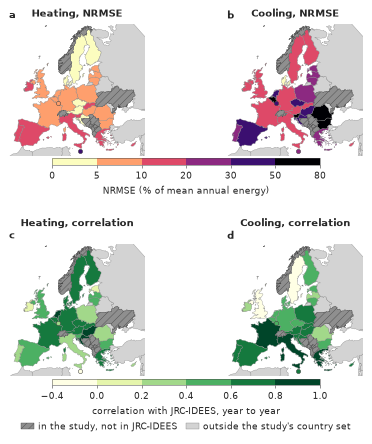

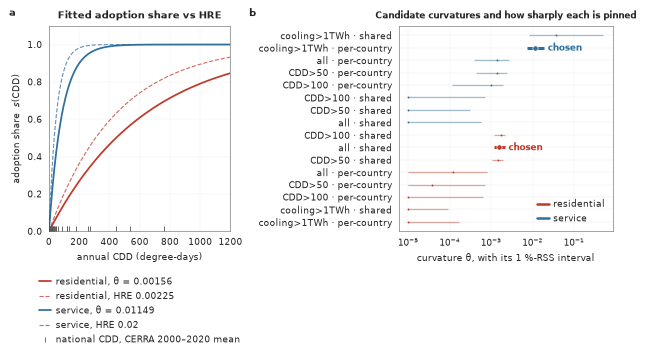

In [25]:
from matplotlib.patches import Patch

#: Short forms for the axis; the caption spells out what the distinction is.
SPEC_SHORT = {"FE": "per-country", "noFE": "shared"}

SECTOR_COLOR = {"res": "#C0392B", "srv": "#2E6F9E"}
HEAT_COLOR, COOL_COLOR = "#C0392B", "#2E6F9E"

# ── S9's two map scales ─────────────────────────────────────────────────────────────────
# Classed rather than continuous: a reader cannot rank countries off a continuous fill, and the
# question these maps answer is "how badly, roughly, and where".
#
# Each scale is SHARED between the two fuels, so the pair states the comparison directly -- heating
# in the light classes, cooling in the dark ones. Six classes populate as heating 6/13/8/0/1/0 and
# cooling 1/0/10/7/8/2, so heating keeps three classes of internal contrast rather than flattening.
#
# The two rows deliberately use different hues because they run in OPPOSITE senses -- dark is worse
# above, better below -- and because red and blue are the fuels' identity colours everywhere else
# in this section and must not double as a magnitude ramp.
NRMSE_BINS = [0, 5, 10, 20, 30, 50, 80]
CORR_BINS = [-0.4, 0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
NRMSE_CMAP = plt.get_cmap("magma_r", len(NRMSE_BINS) - 1)
CORR_CMAP = plt.get_cmap("YlGn", len(CORR_BINS) - 1)

# The two "no value" fills, deliberately different colours: a country the study models but
# JRC-IDEES does not cover is not the same as a country the study never touches. Greys rather than
# hues, so neither can be read as a class of either data ramp, and separated by LIGHTNESS so the
# distinction survives greyscale printing and colour-blind vision.
NO_JRC_COLOR = "#8F8F8F"
OUTSIDE_COLOR = "lightgrey"     # what `plot_country_choropleth` paints where there is no value


#: States too small to read as a filled polygon at 88 mm, drawn as a circle instead. Malta is not
#: a cosmetic case: it is the largest heating error (43 %) and the only negative heating
#: correlation, so leaving it invisible would hide the extreme the map exists to show.
SMALL_STATES = ("MT", "LU")


def _small_state_markers(ax, values_by_iso2, cmap, norm):
    """Circles at the small states' own positions -- no offset, no leader; the caption names them."""
    for iso in SMALL_STATES:
        if iso not in values_by_iso2.index:
            continue
        # representative_point rather than centroid: the latter warns on a geographic CRS, and the
        # difference is far below the size of the marker.
        point = countries.loc[countries["ISO2"] == iso, "geometry"].representative_point().iloc[0]
        ax.plot(point.x, point.y, "o", ms=3.4, color=cmap(norm(values_by_iso2[iso])),
                mec="0.25", mew=0.4, zorder=4)


def _map_panel(ax, values_by_iso2, cmap, bins, title):
    """One classed choropleth, with the two kinds of "no value" in two different greys.

    `plot_country_choropleth` greys any country it has no value for -- but that grey also covers
    Morocco, Turkey and Russia, everything outside the study's country set. The nine countries the
    study models and JRC-IDEES does not cover are therefore repainted in their own darker grey AND
    hatched, so "not studied" and "studied but nothing to evaluate against" differ in two channels
    at once -- the fill separates them at a glance across a whole map, the hatch identifies a single
    country beyond doubt where two greys sit apart on the page.
    """
    inside = (values_by_iso2 >= bins[0]) & (values_by_iso2 <= bins[-1])
    assert inside.all(), (f"{title}: outside the classed scale {bins}: "
                          f"{values_by_iso2[~inside].round(2).to_dict()}")
    norm = mcolors.BoundaryNorm(bins, cmap.N)
    plot_country_choropleth(ax, values_by_iso2, countries, cmap=cmap, norm=norm, legend=False,
                            edgecolor="0.5", linewidth=0.25)
    _small_state_markers(ax, values_by_iso2, cmap, norm)
    countries[countries["ISO2"].isin(NO_JRC_ISO2.values())].plot(
        ax=ax, facecolor=NO_JRC_COLOR, edgecolor="0.25", hatch="////", linewidth=0.25, zorder=3)
    # Every geopandas draw forces aspect "equal" (see the module docstring in plotting_paper), and
    # the overlay is a second one after the choropleth already restored "auto". Left equal, each map
    # shrinks inside its box, the figure's tight bbox comes out ~127 mm, and `fit_width` then grows
    # the whole figure by 1.4x to reach 180 mm -- which is how a 150 mm figure became 212 mm tall.
    set_map_aspect(ax, countries)
    ax.set_title(title, fontsize=FS["title"], fontweight="bold")


def _row_colorbar(fig, axes, cmap, bins, label):
    """One horizontal colorbar under a row of maps, its ticks the class edges."""
    mappable = plt.cm.ScalarMappable(norm=mcolors.BoundaryNorm(bins, cmap.N), cmap=cmap)
    bar = fig.colorbar(mappable, ax=list(axes), orientation="horizontal", fraction=0.055,
                       pad=0.02, aspect=42, shrink=0.62, ticks=bins)
    bar.set_label(label, fontsize=FS["label"])
    bar.ax.tick_params(labelsize=FS["tick"], length=2)
    bar.outline.set_linewidth(0.4)
    return bar


def figure_s9():
    """Row 1: how large the error is, per country. Row 2: whether it is in the right years.

    Maps rather than a modelled-against-observed scatter because that scatter was a diagonal line
    restating its own calibration -- the through-origin heating slope is fitted to reproduce each
    country's mean -- and because both fields have a real spatial structure: heating error is a
    small-HDD, Mediterranean phenomenon, and cooling's correlation is high exactly where cooling is
    large and negative where it is negligible.
    """
    fig, axes = plt.subplots(2, 2, figsize=(WIDTH, 152 * MM),
                             gridspec_kw={"wspace": 0.02, "hspace": 0.55})
    (ax_a, ax_b), (ax_c, ax_d) = axes
    for ax, fuel in ((ax_a, "heating"), (ax_b, "cooling")):
        _map_panel(ax, nrmse_iso2[fuel], NRMSE_CMAP, NRMSE_BINS,
                   f"{fuel.capitalize()}, NRMSE")
    for ax, fuel in ((ax_c, "heating"), (ax_d, "cooling")):
        _map_panel(ax, corr_iso2[fuel], CORR_CMAP, CORR_BINS,
                   f"{fuel.capitalize()}, correlation")
    _row_colorbar(fig, (ax_a, ax_b), NRMSE_CMAP, NRMSE_BINS,
                  "NRMSE (% of mean annual energy)")
    bar = _row_colorbar(fig, (ax_c, ax_d), CORR_CMAP, CORR_BINS,
                        "correlation with JRC-IDEES, year to year")
    # The colorbar's axes must be in the list: `legend_below` measures the tight bbox of the axes
    # it is given, and the maps' bbox stops above the colorbar it was drawn beside.
    legend_below(fig, [ax_c, ax_d, bar.ax],
                 [Patch(facecolor=NO_JRC_COLOR, edgecolor="0.25", hatch="////", linewidth=0.3),
                  Patch(facecolor=OUTSIDE_COLOR, edgecolor="0.5", linewidth=0.3)],
                 ["in the study, not in JRC-IDEES",
                  "outside the study's country set"], ncol=2, gap_pt=2.0)
    panel_letters(fig, list(zip("abcd", [ax_a, ax_b, ax_c, ax_d])))
    # 140 mm, not 180: the four maps are drawn at true (equal-area) aspect, so filling the full width
    # made the figure 212 mm tall, over the 185 mm its caption allows.
    fit_width(fig, target_mm=100)     # after the letters: they sit outside the axes and widen it
    return fig


def figure_s10():
    """a, the fitted adoption curves and where Europe sits on them; b, how sharply theta is pinned."""
    # Wide gutter: panel b's candidate labels are long, and at a narrower wspace they ran into
    # panel a's legend.
    # A wide gutter and a wider right panel: panel b's candidate labels are long and at a narrower
    # setting they ran over panel a's plotting area.
    fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(WIDTH, 66 * MM),
                                     gridspec_kw={"wspace": 0.85, "width_ratios": (1.0, 1.18)})
    grid = np.linspace(0, 1200, 500)
    for sector in COOL_SECTORS:
        ax_a.plot(grid, 1 - np.exp(-THETA[sector] * grid), color=SECTOR_COLOR[sector], lw=1.4,
                  label=f"{SECTOR_LABEL[sector]}, θ = {THETA[sector]:.5f}")
        ax_a.plot(grid, 1 - np.exp(-dc.HRE_THETA[sector] * grid), color=SECTOR_COLOR[sector],
                  lw=0.9, ls="--", alpha=0.75,
                  label=f"{SECTOR_LABEL[sector]}, HRE {dc.HRE_THETA[sector]}")
    # Where the domain actually sits. Without it the curves are unreadable as a statement about
    # Europe: the service curve saturates at ~200, inside the observed range, the residential one
    # not until ~1473, outside it.
    observed_cdd = cdd_annual.loc[COOL_YEARS, FITTED].mean()
    ax_a.plot(observed_cdd.values, np.full(len(observed_cdd), 0.02), "|", ms=4, mew=0.7,
              color="0.35", label="national CDD, CERRA 2000–2020 mean")
    ax_a.set_xlim(0, 1200)
    ax_a.set_ylim(0, 1.10)                      # headroom so the legend clears the tick rug
    ax_a.set_xlabel("annual CDD (degree-days)", fontsize=FS["label"])
    ax_a.set_ylabel("adoption share  $s(\\mathrm{CDD})$", fontsize=FS["label"])
    ax_a.set_title("Fitted adoption share vs HRE", fontsize=FS["title"], fontweight="bold")
    ax_a.tick_params(labelsize=FS["tick"])
    ax_a.grid(color="0.93", lw=0.3)
    ax_a.set_axisbelow(True)
    # The key goes BELOW the panel (after fit_width): at 7 pt no corner of the axes is free -- the
    # service curve fills the top, the residential one the middle, the tick rug the bottom.

    # b -- every candidate the rule considered. The bar is the set of curvatures fitting within 1 %
    # of that candidate's own best: how sharply the data pin theta, NOT a spread between countries.
    order, labels = [], []
    for sector in COOL_SECTORS:
        block = cool_candidates[cool_candidates.sector == sector].sort_values("theta")
        for _, row in block.iterrows():
            order.append(row)
            labels.append(f"{row.group} · {SPEC_SHORT[row.spec]}")
    for y, row in enumerate(order):
        colour = SECTOR_COLOR[row.sector]
        ax_b.plot([row.band_lo, row.band_hi], [y, y], color=colour,
                  lw=2.4 if row.chosen else 1.0, alpha=1.0 if row.chosen else 0.45,
                  solid_capstyle="butt", zorder=2)
        ax_b.plot(row.theta, y, "o" if row.chosen else ".", ms=4.2 if row.chosen else 3.0,
                  color=colour, mec="white" if row.chosen else "none", mew=0.5, zorder=3)
        if row.chosen:
            ax_b.annotate("chosen", (row.band_hi, y), xytext=(3, 0), textcoords="offset points",
                          fontsize=FS["tick"], va="center", color=colour, fontweight="bold")
    ax_b.set_yticks(range(len(order)))
    ax_b.set_yticklabels(labels, fontsize=FS["tick"])
    ax_b.set_xscale("log")
    ax_b.set_xlabel("curvature θ, with its 1 %-RSS interval", fontsize=FS["label"])
    ax_b.set_title("Candidate curvatures and how sharply each is pinned", fontsize=FS["label"],
                   fontweight="bold")
    ax_b.tick_params(labelsize=FS["tick"])
    ax_b.grid(color="0.93", lw=0.3, axis="x")
    ax_b.set_axisbelow(True)
    ax_b.legend(handles=[plt.Line2D([], [], color=SECTOR_COLOR[s], lw=2.0, label=SECTOR_LABEL[s])
                         for s in COOL_SECTORS],
                fontsize=FS["tick"], frameon=False, loc="lower right")
    panel_letters(fig, [("a", ax_a), ("b", ax_b)])
    # 178.5 rather than the 180 default: savefig's tight bbox comes out ~1.7 mm wider than
    # `fit_width` measures for this figure, which put the PDF page over the 181.5 mm limit.
    fit_width(fig, target_mm=178.5)
    legend_below(fig, [ax_a], *ax_a.get_legend_handles_labels(), ncol=1)   # two columns overran the page
    return fig


with publication_rc():
    for _stem, _builder in (("S9_demand_model_performance", figure_s9),
                            ("S10_cooling_adoption_terms", figure_s10)):
        _fig = _builder()
        save(_fig, _stem, FIGS)
        plt.show()


## 7 · One figure per conversion step

What each conversion emits, one figure per quantity, with the annual field above the four seasons so
a quantity's level and its seasonal cycle are read in one frame rather than across two figures.

**How the rows are scaled.** The four seasonal rows share one absolute scale, so a country rendering
the same colour in two rows really does hold the same value and the seasonal cycle reads down the
column. The annual row is deliberately **not** on that scale: it is a yearly total against per-season
totals, roughly four times the size by construction, and putting it on the seasons' scale would
saturate it. Column 1 is the level at +1.5 °C; columns 2 and 3 are the median change across the nine
chains, as a percentage.

**Resolution follows the data.** Solar and wind are gridded capacity factors. Demand, run-of-river
and reservoir inflow are national totals — they are never gridded, so they are drawn as choropleths
rather than interpolated onto a grid they do not have. Countries with no fleet are grey, not zero.

**Reservoir inflow, not dispatch.** Inflow is the resource the climate delivers; dispatch is the
decision the optimiser makes with it, and it appears in Supplementary Note 2 with the rest of the
system configuration. A constant inflow redistributed across the year would show up as a change in
dispatch, which must not be read as a climate impact.

### S11: heating demand

> **Supplementary Figure 11 | Heating demand.** Rows are the annual mean above the four
> meteorological seasons; columns are the level at +1.5 °C and the median change across nine chains
> at +2.0 °C and +3.0 °C. National totals, drawn as choropleths at the resolution the demand model
> produces. The four seasonal rows share one absolute scale; the annual row, a yearly total against
> per-season totals, has its own. Hatching marks countries where fewer than six of nine chains agree
> on the sign of the change.

### S12: cooling demand

> **Supplementary Figure 12 | Cooling demand.** Rows, columns, scales and hatching as in
> Supplementary Fig. S11.

### S13: solar power

> **Supplementary Figure 13 | Solar power.** Gridded capacity factor rather than a national total.
> Rows, columns and hatching as in Supplementary Fig. S11, but **all five rows share one absolute
> scale and one change scale**: a capacity factor is the same dimensionless quantity annually and
> seasonally, so the rows are directly comparable. On that common scale the winter change dominates
> and the summer one looks faint, which is the seasons genuinely differing by about a factor of
> three rather than the scale suppressing anything.

### S14: wind power

> **Supplementary Figure 14 | Wind power.** Gridded capacity factor; rows, columns, scales and
> hatching as in Supplementary Fig. S13, including the shared absolute and change scales.

### S15: run-of-river generation

> **Supplementary Figure 15 | Run-of-river generation.** National totals. Rows, columns, scales and
> hatching as in Supplementary Fig. S11.

### S16: reservoir inflow

> **Supplementary Figure 16 | Reservoir inflow.** The water the climate delivers to the reservoir
> fleet, as national totals — not the dispatch decided from it, which is Supplementary Note 2. Rows,
> columns, scales and hatching as in Supplementary Fig. S11.

In [33]:
# ── Country-level generation on the paper's run, plus the gridded capacity factors ──────
started = time.perf_counter()
energy_annual = load_gwl_grids("")
energy_seasonal = load_gwl_grids("", seasonal=True)

# MONTHLY totals, cached on disk (cordex2energy_analysis.figure_cache): every field below slices
# whole-year GWL windows and whole months, so they are an exact substitute for the 3-hourly and
# daily series (checked to 1e-9), and a rerun skips the pass over the raw files entirely.
country_output_by_model = country_monthly(
    {m: PATH_EXTREMES / "residual_load" / f"{m}_{CLIMATE_SCENARIO}" / RUN_TAG for m in models},
    ("components.nc",))
_INFLOW = PATH_GWL / "c2e_cache" / f"c2e_hydro_inflow_{CLIMATE_SCENARIO}.nc"
c2e_hydro = cached("c2e_hydro_inflow_monthly",
                   lambda: {"hydro_inflow": monthly_totals(xr.open_dataarray(_INFLOW))},
                   key={"version": 1}, files=[_INFLOW], code=False)

# Measured across the nine chains, +1.5 -> +3.0 C: run-of-river reaches 15.6 %, inflow 17.7 % and
# dispatch 17.6 %, so ONE edge set covers all three with nothing in the extend arrows, and sharing
# it makes the three rows directly comparable. These are Figure 2's hydro edges, so the SI and the
# main figure put the same quantity on the same scale.
HYDRO_BINS = [-20, -10, -5, -2, -1, 1, 2, 5, 10, 20]


def hydro_field(expression, period, months=None):
    return mask_structural_zeros(compute_country_gwl_field(
        country_output_by_model, period_defs, period, expression, months=months))


def inflow_field(period, months=None):
    return mask_structural_zeros(compute_c2e_gwl_field(
        c2e_hydro, period_defs, period, "hydro_inflow", months=months))


GENERATION = ["Solar power", "Wind power", "Run-of-river generation", "Reservoir inflow",
              "Reservoir dispatch"]
GEN_GRID_VARIABLE = {"Solar power": "pv", "Wind power": "wind"}
GEN_COUNTRY_FN = {
    "Run-of-river generation": lambda p, m: hydro_field(lambda d: d["gen_hydro_ror"], p, m),
    "Reservoir inflow": inflow_field,
    "Reservoir dispatch": lambda p, m: hydro_field(lambda d: d["reservoir_dispatch_gwh"], p, m),
}

# Compute each country field ONCE. Every one is a 20-year reduction over 3-hourly data, so
# rebuilding them per figure (and again in the verification cell) would triple the runtime.
gen_annual = {label: {p: fn(p, None) for p in period_names}
              for label, fn in GEN_COUNTRY_FN.items()}
gen_seasonal = {label: {s: {p: fn(p, SEASON_MONTHS[s]) for p in period_names}
                        for s in SEASON_ORDER}
                for label, fn in GEN_COUNTRY_FN.items()}
print(f"generation sources ready [{time.perf_counter() - started:.0f}s]")


def generation_row(label, *, season=None, unit_suffix="yr", row_label=None):
    if label in GEN_GRID_VARIABLE:
        grids = energy_seasonal if season is not None else energy_annual
        variable = GEN_GRID_VARIABLE[label]

        def field(period, variable=variable, grids=grids, season=season):
            da = grids[period][variable]
            return da.sel(season=season) if season is not None and "season" in da.dims else da

        return MapRow(label=row_label or label, field=field, cmap=CLIMATE_CMAPS[variable],
                      kind="grid", unit=CLIMATE_UNITS[variable], change="percent",
                      clabel="% change")
    cache = gen_annual[label] if season is None else gen_seasonal[label][season]
    return MapRow(label=row_label or label, field=lambda p, c=cache: c[p], kind="country",
                  cmap=QUANTITY_CMAP["Hydro"], unit=f"TWh {unit_suffix}$^{{-1}}$", change="percent",
        bins=HYDRO_BINS)

[cache] hit   country_monthly_components  (30 MB, 0s)
[cache] hit   c2e_hydro_inflow_monthly  (0 MB, 0s)
generation sources ready [5s]


In [34]:
# ── The demand product, rebuilt from the raw hourly output ──────────────────────────────
# NOT from energy/analysis/c2e_cache/c2e_{heating,cooling}_rcp85.nc: that cache predates the
# adopted demand model. This is the same construction paper_figures_publication.ipynb uses.
started = time.perf_counter()


# MONTHLY sums of the DAILY-MEAN demand (GW), cached on disk (cordex2energy_analysis.figure_cache).
# Every field below slices whole-year GWL windows and whole months, so monthly totals are an exact
# substitute for the daily series (checked to 1e-9), and a rerun skips the hourly files entirely.
demand_by_month = demand_monthly(PATH_DEMAND, models, CLIMATE_SCENARIO)
NAME_TO_ISO2 = build_c2e_name_to_iso2(load_tyndp_country_codes(
    PATH_EXTREMES / "tyndp" / "Demand_Scenarios_TYNDP_2024_After_Public_Consultation.xlsb"))
for name, array in demand_by_month.items():
    demand_by_month[name] = array.assign_coords(
        country=[NAME_TO_ISO2.get(str(c), str(c)) for c in array["country"].values])

residual_by_model = country_monthly(
    {m: PATH_EXTREMES / "residual_load" / f"{m}_{CLIMATE_SCENARIO}" / RUN_TAG for m in models},
    ("residual_load.nc",))
print(f"demand product loaded [{time.perf_counter() - started:.0f}s]")

# Figure 3's edges, so the same quantity sits on the same scale in the SI and the main text.
# Measured maxima across the nine chains: heating 56 %, cooling 226 %, residual load 12.1 TWh/yr.
DEMAND_BINS = {
    "Heating demand": [-50, -30, -20, -15, -10, -1, 1, 10, 15, 20, 30, 50],
    "Cooling demand": [-200, -150, -100, -50, -25, -1, 1, 25, 50, 100, 150, 200],
    "Residual load": [-10, -5, -2, -0.5, 0.5, 2, 5, 10],            # TWh/yr, ABSOLUTE
}
# A season carries a fraction of the annual change, so the absolute residual-load edges are halved
# for the seasonal figure; the per-bin counts printed below confirm nothing piles into the arrows.
DEMAND_BINS_SEASONAL = {**DEMAND_BINS, "Residual load": [-5, -2, -1, -0.25, 0.25, 1, 2, 5]}
assert all(np.allclose(sorted(-np.array(e)), e)
           for e in list(DEMAND_BINS.values()) + list(DEMAND_BINS_SEASONAL.values())), \
    "every edge set must be symmetric about zero"


DEMAND_ROWS = ["Heating demand", "Cooling demand", "Residual load"]
# Residual load is BrBG_r for the same reason as Figure 3: it is the only DIVERGING level here,
# and sharing RdBu_r with its own change column made the two read as one thing. Teal for
# surplus, brown for deficit; the change columns own red/blue.
DEMAND_CMAP = QUANTITY_CMAP          # one definition, shared with Figures 2 and 3
# scale=24e-3: the monthly totals are sums of daily means in GW, so a period-mean total is
# GW*24 h = GWh -> TWh.
DEMAND_FN = {
    "Heating demand": lambda p, m: compute_c2e_gwl_field(demand_by_month, period_defs, p, "heating",
                                                         scale=24e-3, months=m),
    "Cooling demand": lambda p, m: compute_c2e_gwl_field(demand_by_month, period_defs, p, "cooling",
                                                         scale=24e-3, months=m),
    # NOT mask_structural_zeros here: residual load can legitimately pass through zero, and a
    # country that happens to balance exactly must not be greyed out as though it had no data.
    "Residual load": lambda p, m: compute_country_gwl_field(
        residual_by_model, period_defs, p, lambda d: d["residual_load"], months=m),
}

# Computed once. Each is a 20-year reduction over 3-hourly country series, so rebuilding them per
# figure (and again in the verification cell) would triple the runtime.
started = time.perf_counter()
demand_annual = {label: {p: fn(p, None) for p in period_names} for label, fn in DEMAND_FN.items()}
demand_seasonal = {label: {s: {p: fn(p, SEASON_MONTHS[s]) for p in period_names}
                           for s in SEASON_ORDER}
                   for label, fn in DEMAND_FN.items()}
print(f"demand and residual-load fields built [{time.perf_counter() - started:.0f}s]")


def demand_row(label, *, season=None, unit_suffix="yr", row_label=None):
    bins = (DEMAND_BINS_SEASONAL if season is not None else DEMAND_BINS)[label]
    cache = demand_annual[label] if season is None else demand_seasonal[label][season]
    absolute = label == "Residual load"
    return MapRow(
        label=row_label or label, field=lambda p, c=cache: c[p], kind="country",
        cmap=DEMAND_CMAP[label], unit=f"TWh {unit_suffix}$^{{-1}}$",
        change="absolute" if absolute else "percent", bins=bins,
        abs_center=0 if absolute else None,
        # No override: the builder's default is now RdBu_r for every row, which is the rule
        # Figures 2 and 3 carry — red is more of the quantity the row plots.
        # No clabel override: the default is already "change (TWh / <unit>)". The sign
        # convention lives in the caption, matching Figures 2 and 3.
        clabel=None)

[cache] hit   demand_monthly  (7 MB, 0s)
[cache] hit   country_monthly_residual_load  (3 MB, 0s)
demand product loaded [0s]
demand and residual-load fields built [4s]


  S11_heating_demand           143.3 x 193.9 mm   panel 34.9 mm   pdf 1154 kB  png 2102 kB
  S12_cooling_demand           146.7 x 193.8 mm   panel 34.7 mm   pdf 1151 kB  png 2081 kB
  [ticks] wanted 4 inside [0.056257, 0.242588] but the closest round set has 3: [np.float64(0.08), np.float64(0.16), np.float64(0.24)]
  S13_solar_power              146.7 x 193.8 mm   panel 35.3 mm   pdf 5317 kB  png 5243 kB
  S14_wind_power               146.7 x 193.8 mm   panel 35.3 mm   pdf 6881 kB  png 6420 kB
  S15_run_of_river             143.4 x 193.9 mm   panel 34.9 mm   pdf 1164 kB  png 2004 kB
  S16_reservoir_inflow         144.8 x 193.9 mm   panel 34.9 mm   pdf 1182 kB  png 1983 kB
  S11_heating_demand     1 change scale(s) (shared bin edges), annual row on its own absolute scale
  S12_cooling_demand     1 change scale(s) (shared bin edges), annual row on its own absolute scale
  S13_solar_power        one change scale +-13.74 %, one absolute scale
  S14_wind_power         one change scale +-10.

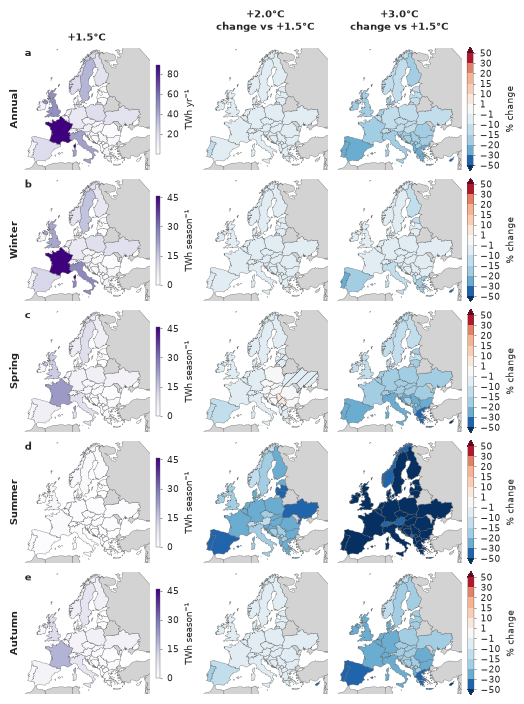

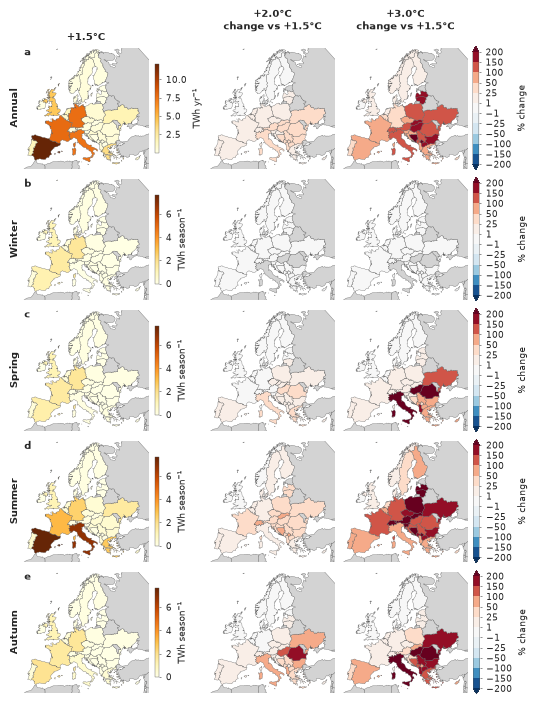

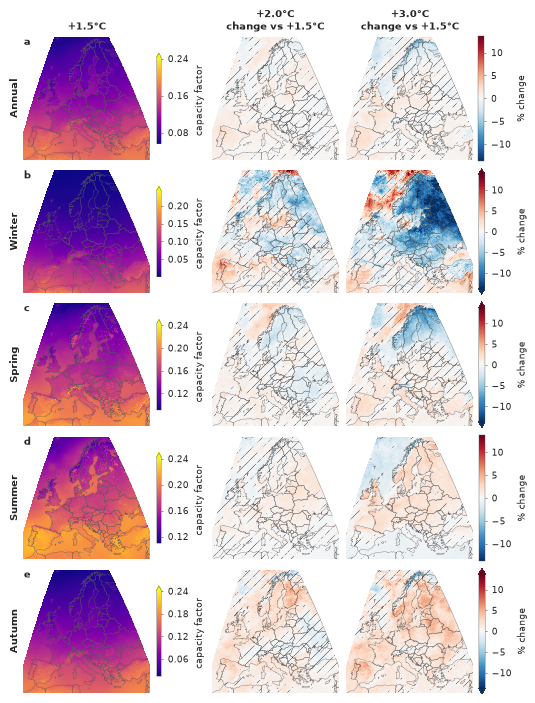

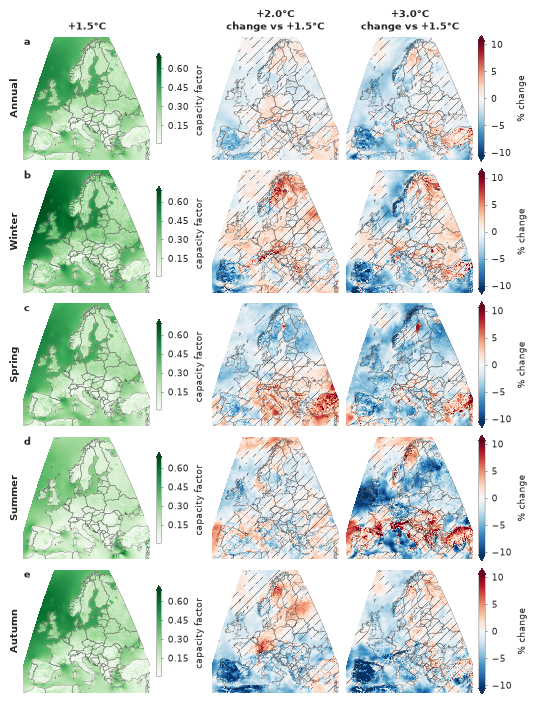

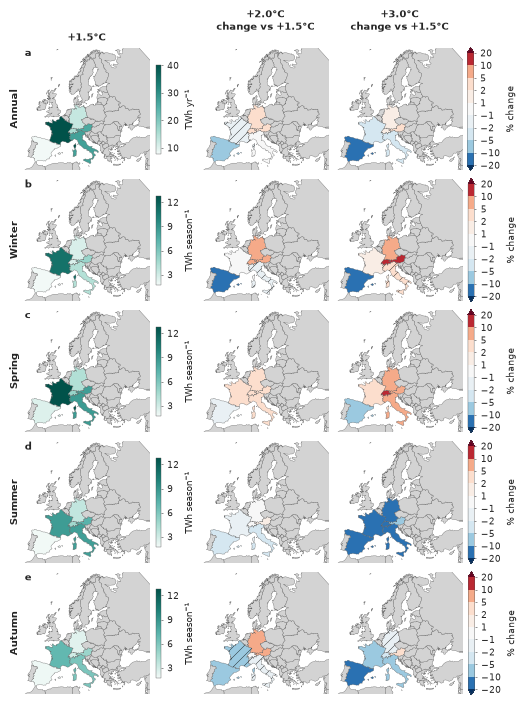

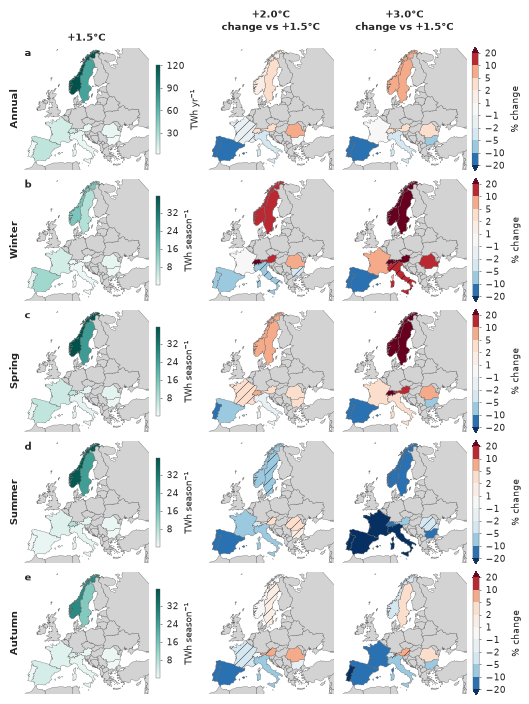

In [35]:
# ── S11-S16: the conversion steps, one figure each ───────────────────────────────────────
SEASONAL_ROWS = list(range(1, 1 + len(SEASON_ORDER)))

# Two scaling regimes, and which one a figure takes is decided by its UNIT, not by its style.
#   country rows -- TWh per YEAR above TWh per SEASON. The annual row is four times the size by
#                   construction, so it keeps its own absolute scale while the seasons share theirs.
#                   Their change columns already share one ramp through fixed bin edges.
#   gridded rows -- a capacity factor: dimensionless, and the same quantity annually or seasonally.
#                   Every row shares, absolute AND change. Without the second the five rows came out
#                   at +-3, +-11, +-7, +-3.5 and +-4.5 %, so one red meant 2 % in one row and 8 % in
#                   another; without the first the annual row sat at 0.19 against the seasons' 0.24.
COUNTRY_SCALING = dict(share_abs_scale=SEASONAL_ROWS)
GRID_SCALING = dict(share_abs_scale=True, share_change_scale=True)

CONVERSION = [
    ("S11_heating_demand", "Heating demand", demand_row, COUNTRY_SCALING),
    ("S12_cooling_demand", "Cooling demand", demand_row, COUNTRY_SCALING),
    ("S13_solar_power", "Solar power", generation_row, GRID_SCALING),
    ("S14_wind_power", "Wind power", generation_row, GRID_SCALING),
    ("S15_run_of_river", "Run-of-river generation", generation_row, COUNTRY_SCALING),
    ("S16_reservoir_inflow", "Reservoir inflow", generation_row, COUNTRY_SCALING),
]

scale_report = {}
with publication_rc():
    for stem, label, row_builder, scaling in CONVERSION:
        rows = [row_builder(label, row_label="Annual")] + [
            row_builder(label, season=season, unit_suffix="season", row_label=season_label(season))
            for season in SEASON_ORDER]
        fig, row_axes = gwl_maps(rows, countries_print, STYLE, sign_agreement,
                                 height_mm=196, **scaling)
        # What the rows ACTUALLY ended up on, read off the drawn colorbars rather than assumed:
        # the defect this replaced was invisible until the figure was looked at.
        scale_report[stem] = dict(
            change_limits={round(bar.norm.vmax, 6) for bar in fig.change_colorbars},
            abs_limits={round(ax.images[0].norm.vmax, 6) for ax in row_axes if ax.images})
        panel_letters(fig, list(zip("abcde", row_axes)), inside=True)
        save(fig, stem, FIGS)
        plt.show()

# The colorbar fix, asserted. A gridded figure must put every row on ONE change scale and ONE
# absolute scale; a country figure must NOT put the annual row on the seasons' absolute scale.
for stem, _, _, scaling in CONVERSION:
    report = scale_report[stem]
    if scaling is GRID_SCALING:
        assert len(report["change_limits"]) == 1, \
            f"{stem}: rows carry different change limits {sorted(report['change_limits'])}"
        assert len(report["abs_limits"]) <= 1, \
            f"{stem}: rows carry different absolute limits {sorted(report['abs_limits'])}"
        print(f"  {stem:<22} one change scale +-{max(report['change_limits']):.2f} %, "
              f"one absolute scale")
    else:
        print(f"  {stem:<22} {len(report['change_limits'])} change scale(s) "
              f"(shared bin edges), annual row on its own absolute scale")